# EDA na Prática

Nas aulas 9 e 10 vimos os quatro princípios da EDA (estrutural, distribucional, relacional e detecção de outliers/anomalias), como tratar dados ausentes e outliers, e como fazer análise descritiva, bivariada e multivariada. Hoje é a hora de **aplicarmos na prática**. Durante a primeira hora da aula, serão apresentadas as técnicas no dataset *Heart Disease* (UCI) e depois **cada aluno** irá aplicar as técnicas no dataset que foi escolhido semana passada.

*Relembrando*: a EDA não é uma linha reta

A EDA costuma ser apresentada como uma sequência de etapas (estrutura → tratamento → descrição → relação), mas na prática ela é **iterativa**: às vezes tratamos um outlier, olhamos a estatística descritiva de novo, e percebemos que precisa voltar atrás. Hoje vamos deixar isso explícito: olhamos a estatística descritiva **antes** de tratar dados ausentes/outliers (pra saber *como* tratar) e **depois** (pra confirmar o efeito do tratamento).

## Como funcionará a atividade

- **Duração:** ~1h40min
- **Formato:** individual
- **Passo 1:** acompanhem a demonstração no dataset Heart Disease.
- **Passo 2:** importem o dataset que vocês escolheram e enviaram anteriormente.
- **Passo 3:** repliquem o mesmo ciclo no dataset escolhido, respondendo às perguntas guiadas.
- **Uso de IA:** permitido, conforme o Plano de Ensino — documentem na seção final.

## Setup de Bibliotecas e Dados

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)

COR_NEUTRA = "lightgray"     # convenção: cinza-claro pra tudo que é "pano de fundo" genérico
COR_CONTEXTO = "#e9d4d0"    # rosa-claro pra pano de fundo / classe de referência
COR_DESTAQUE = "#2d223a"    # roxo pra classe de interesse / "o personagem da história"
COR_ALERTA = "tab:red"       # exceção deliberada: outliers/pontos de atenção

## Carregando o Dataset

In [2]:
import kagglehub
import pandas as pd
import os


path = kagglehub.dataset_download(
    "lucasyukioimafuko/brasileirao-serie-a-2006-2022"
)

print("Path to dataset files:", path)

df = pd.read_csv(
    os.path.join(path, "brasileirao.csv")
)

df.head()

100%|██████████| 7.54k/7.54k [00:00<00:00, 11.9MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/lucasyukioimafuko/brasileirao-serie-a-2006-2022/versions/19


,season,place,team,points,played,won,draw,loss,goals,goals_taken,goals_diff
0,2003,1,Cruzeiro,100,46,31,7,8,102,47,55
1,2003,2,Santos,87,46,25,12,9,93,60,33
2,2003,3,São Paulo,78,46,22,12,12,81,67,14
3,2003,4,São Caetano,74,46,19,14,13,53,37,16
4,2003,5,Coritiba,73,46,21,10,15,67,58,9


## 1. Princípio Estrutural

Antes de qualquer análise, precisamos entender a "anatomia" dos dados: quantas linhas e colunas temos, que tipo de dado cada coluna guarda, se há valores faltantes e se há duplicadas.

**Antes de rodar:** O dataset do Campeonato Brasileiro possui informações sobre temporada, posição, time, pontos, jogos disputados, vitórias, empates, derrotas, gols marcados, gols sofridos e saldo de gols. com 450 linhas e 11 colunas

### Dimensão e Tipos de Dados

In [3]:
df.shape

(450, 11)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 450 entries, 0 to 449
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   season       450 non-null    int64 
 1   place        450 non-null    int64 
 2   team         450 non-null    object
 3   points       450 non-null    int64 
 4   played       450 non-null    int64 
 5   won          450 non-null    int64 
 6   draw         450 non-null    int64 
 7   loss         450 non-null    int64 
 8   goals        450 non-null    int64 
 9   goals_taken  450 non-null    int64 
 10  goals_diff   450 non-null    int64 
dtypes: int64(10), object(1)
memory usage: 38.8+ KB


In [ ]:
df.describe()

,season,place,points,played,won,draw,loss,goals,goals_taken,goals_diff
count,450.000000,450.000000,450.000000,450.000000,450.000000,450.000000,450.000000,450.000000,450.000000,450.000000
mean,2013.284444,10.762222,53.331111,39.044444,14.362222,10.315556,14.366667,50.031111,50.044444,-0.013333
std,6.442411,5.970148,12.748524,2.556755,4.383091,2.623855,4.403506,12.788459,12.446868,16.605331
min,2003.000000,1.000000,15.000000,37.000000,1.000000,3.000000,3.000000,18.000000,19.000000,-57.000000
25%,2008.000000,6.000000,45.000000,38.000000,11.000000,8.000000,11.000000,41.000000,41.000000,-10.000000
50%,2013.000000,11.000000,53.000000,38.000000,14.000000,10.000000,14.000000,49.000000,48.000000,-1.000000
75%,2019.000000,16.000000,61.000000,38.000000,17.000000,12.000000,17.000000,58.000000,58.000000,10.750000
max,2024.000000,24.000000,100.000000,46.000000,31.000000,18.000000,29.000000,103.000000,92.000000,55.000000


### Duplicadas

In [ ]:
df.duplicated().sum()

np.int64(0)

### Renomeando o atributo alvo para facilitar a interpretação

Criando uma variável categórica para facilitar a interpretação

Como o dataset não possui uma variável-alvo natural, foi criada uma variável categórica a partir do saldo de gols. Ela indica se, naquela temporada, o clube terminou a competição com saldo de gols positivo ou não. Essa transformação permite comparar o desempenho de equipes com diferentes características ofensivas e defensivas.

In [ ]:
df["saldo_resultado"] = np.where(
    df["goals_diff"] > 0,
    "Saldo positivo",
    "Saldo não positivo"
)

df["saldo_resultado"].value_counts()

,count
saldo_resultado,
Saldo não positivo,237
Saldo positivo,213


## 2. Dados Faltantes

In [ ]:
df.isna().sum()

,0
season,0
place,0
team,0
points,0
played,0
won,0
draw,0
loss,0
goals,0
goals_taken,0


**Discussao:** Alguma feature tem dados ausentes nos seus dados?

*Resposta*: Não possui dados faltantes

#### Identificando o mecanismo de dados ausentes

**Conhecimento de Domínio**


Pela fonte de dados observamos que:


*Como os dados foram coletados:*
- Provavelmemte atravez do site do Ge, ou algum aplicativo de futebol que tenham esses dados,como flash Score,Sofascore, etc...

*Qual a natureza da fonte de dados:*
- estou lidando com dados históricos de eventos esportivos,os registros representam jogos realizados em diferentes temporadas, envolvendo diversos clubes, estádios e contextos

**As ausencias ocorrem juntas?**




Colunas com ausentes: []
Series([], dtype: float64)


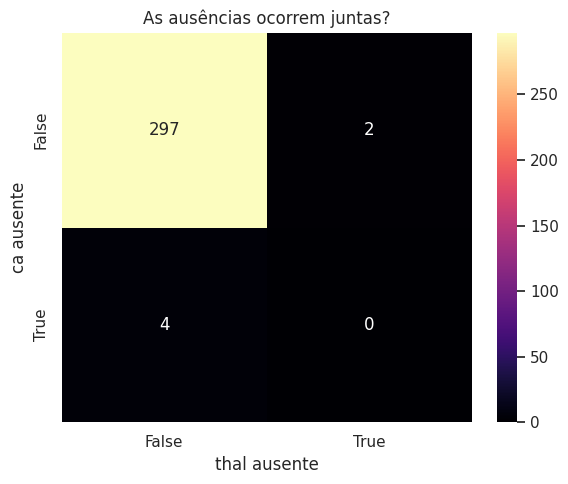

In [ ]:
tabela_contingencia = pd.crosstab(df[cols_com_ausentes[0]].isna(), df[cols_com_ausentes[1]].isna(),
            rownames=[f"{cols_com_ausentes[0]} ausente"], colnames=[f"{cols_com_ausentes[1]} ausente"])

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(tabela_contingencia, annot=True, fmt="d", cmap="magma", ax=ax)
ax.set_title("As ausências ocorrem juntas?")
plt.tight_layout()
plt.show()

**Pra discutir:** quantas linhas têm as duas colunas ausentes ao mesmo tempo? Isso muda a hipótese sobre o mecanismo de ausência (MCAR/MAR/MNAR), ou parecem eventos independentes?

*Relembrando:*
- MCAR: Mecanismo Aleatório e sem viés
- MAR: Mecanismo Randômico e com viés possível de corrigir
- MNAR: Mecanismo Não Randômico relacionada a própria feature

- *Se supormos que a ausência depende do próprio valor que está faltando*: por exemplo, o paciente não fez o exame porque já se suspeitava (por sinais clínicos observados previamente) que o resultado seria anormal, e o exame extra não seria necessário, isso seria classificado como **MNAR**.
- *Se supormos que a ausência depende de algo externo ao valor em si*: por exemplo, o protocolo de coleta decidiu não solicitar aquele exame, ou o custo do procedimento limitou a coleta, independente do que o resultado provavelmente seria — isso seria classificado como **MAR** (ou até **MCAR**, se a decisão for arbitrária e não sistemática).

Não dá pra decidir entre as duas só olhando os dados — é exatamente o tipo de situação em que testes estatísticos (como o teste de MCAR) e conhecimento de domínio real (falar com quem coletou os dados) resolveriam a dúvida. Na ausência disso, seguimos com a opção mais conservadora na hora de tratar.

**Nota para quando vocês replicarem no dataset de vocês:** se o dataset escolhido tiver *muitas* colunas com *muitos* ausentes, aí sim uma correlação (ou um heatmap) entre os indicadores de ausência passa a fazer sentido. O problema neste caso foi o volume pequeno, não a técnica em si.

## 3. Princípio Distribucional

Ainda com os dados originais (sem tratar ausentes ou outliers), vamos calcular as estatísticas descritivas e olhar as distribuições. Esse retrato "antes" é o que vai *orientar as decisões de tratamento* na próxima seção. Por exemplo, se uma variável for muito assimétrica, faz mais sentido imputar com a mediana do que com a média.

In [ ]:
VARS_QUANT = ["points", "played", "won", "draw", "loss", "goals", "goals_taken", "goals_diff"]
VARS_QUALI = ["team", "place", "season"]

desc = df[VARS_QUANT].describe().T
desc["skewness"] = df[VARS_QUANT].skew()
desc["kurtosis"] = df[VARS_QUANT].kurtosis()

(
    desc[["mean", "50%", "std", "min", "max", "skewness", "kurtosis"]]
    .rename(columns={"50%": "median"})
    .round(2)
    .style.format(precision=2)
    .background_gradient(cmap="magma", subset=["skewness", "kurtosis"])
)

,mean,median,std,min,max,skewness,kurtosis
points,53.33,53.00,12.75,15.00,100.00,0.19,0.45
played,39.04,38.00,2.56,37.00,46.00,2.18,3.03
won,14.36,14.00,4.38,1.00,31.00,0.32,0.38
draw,10.32,10.00,2.62,3.00,18.00,0.30,0.19
loss,14.37,14.00,4.40,3.00,29.00,0.18,-0.06
goals,50.03,49.00,12.79,18.00,103.00,0.61,1.21
goals_taken,50.04,48.00,12.45,19.00,92.00,0.60,0.15
goals_diff,-0.01,-1.00,16.61,-57.00,55.00,0.01,0.47


**Pra discutir:** olhando a tabela, quais variáveis já parecem assimétricas (`skewness` acima de 1) ou com cauda pesada (`kurtosis` maior que 2 em módulo)?

Observando a tabela, a variável played é a que apresenta maior assimetria, com skewness de 2,18, indicando uma distribuição puxada para a direita. Ela também apresenta kurtosis de 3,03, sugerindo uma cauda mais pesada.

As variáveis goals e goals_taken apresentam uma assimetria positiva moderada, mas não ultrapassam o valor 1 estabelecido como referência no exercício.

No contexto do futebol, isso pode ser coerente porque o número de partidas disputadas varia entre temporadas, especialmente devido a mudanças no formato da competição ao longo dos anos. Já gols marcados e sofridos podem apresentar alguns valores mais altos em equipes ou temporadas específicas, puxando a distribuição para a direita.

### Distribuições de dados

Onde fizer sentido, comparamos "Sem doença" (rosa) vs. "Com doença" (roxo). Vamos utilizar esta convenção de cor que vamos manter até a análise bivariada.


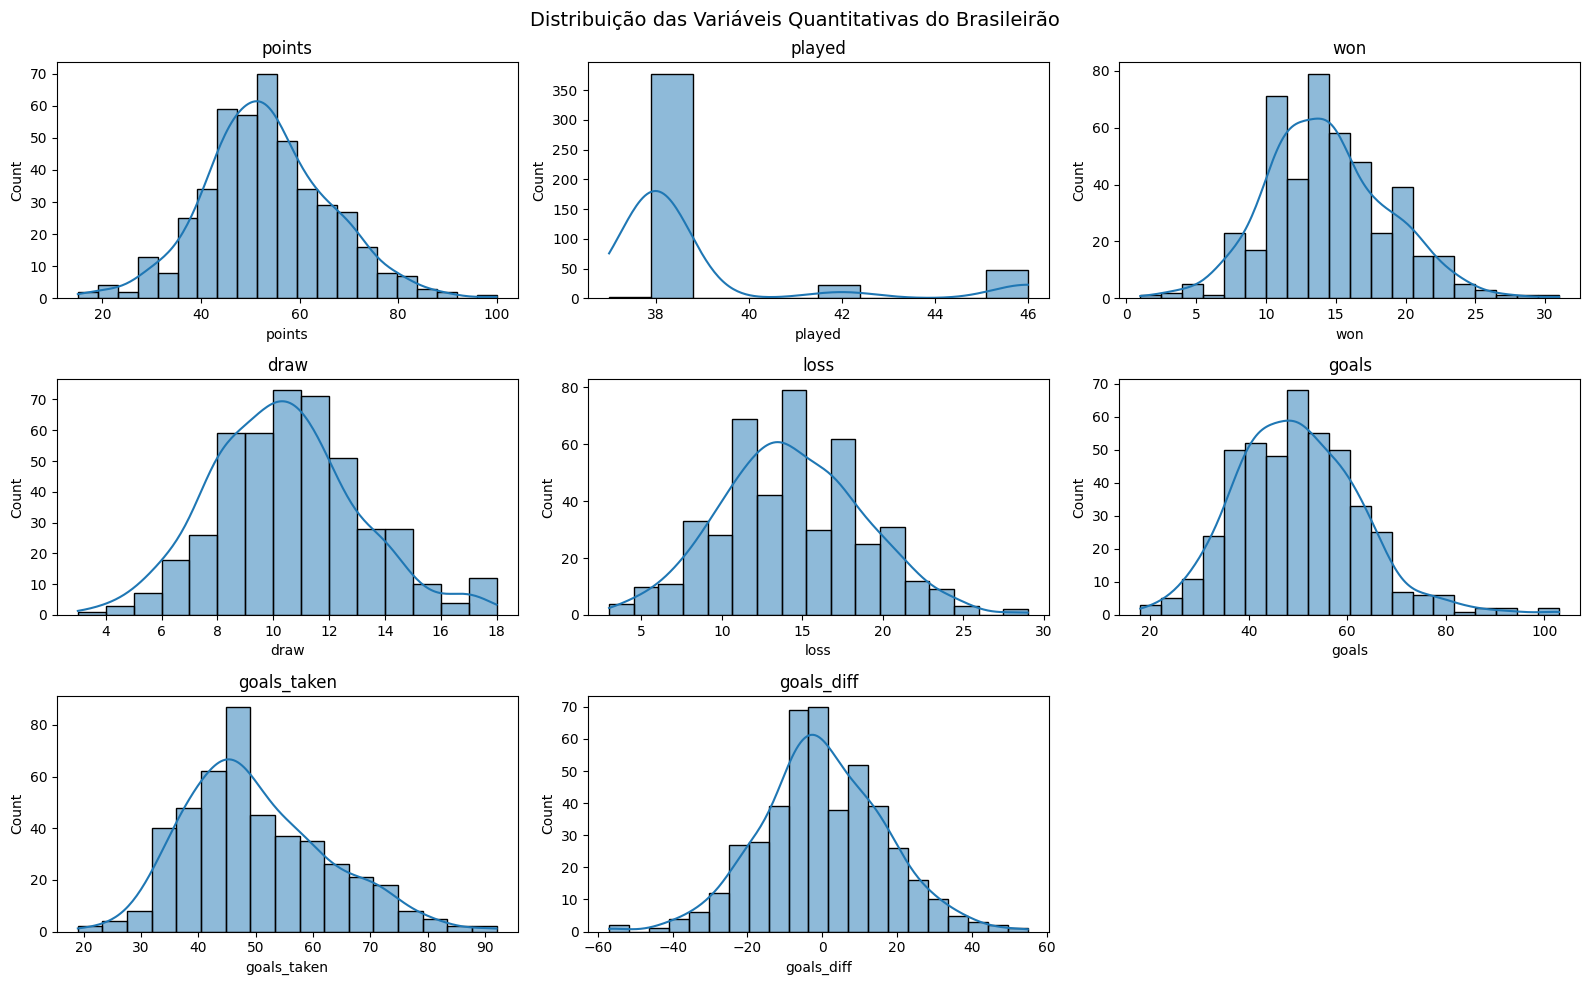

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

VARS_QUANT = ["points", "played", "won", "draw", "loss", "goals", "goals_taken", "goals_diff"]

fig, axes = plt.subplots(3, 3, figsize=(16, 10), sharey=False)
axes = axes.ravel()

for i, col in enumerate(VARS_QUANT):
    sns.histplot(data=df, x=col, kde=True, ax=axes[i])
    axes[i].set_title(col)

for ax in axes[len(VARS_QUANT):]:
    ax.axis("off")

fig.suptitle(
    "Distribuição das Variáveis Quantitativas do Brasileirão",
    fontsize=14
)

plt.tight_layout()
plt.show()

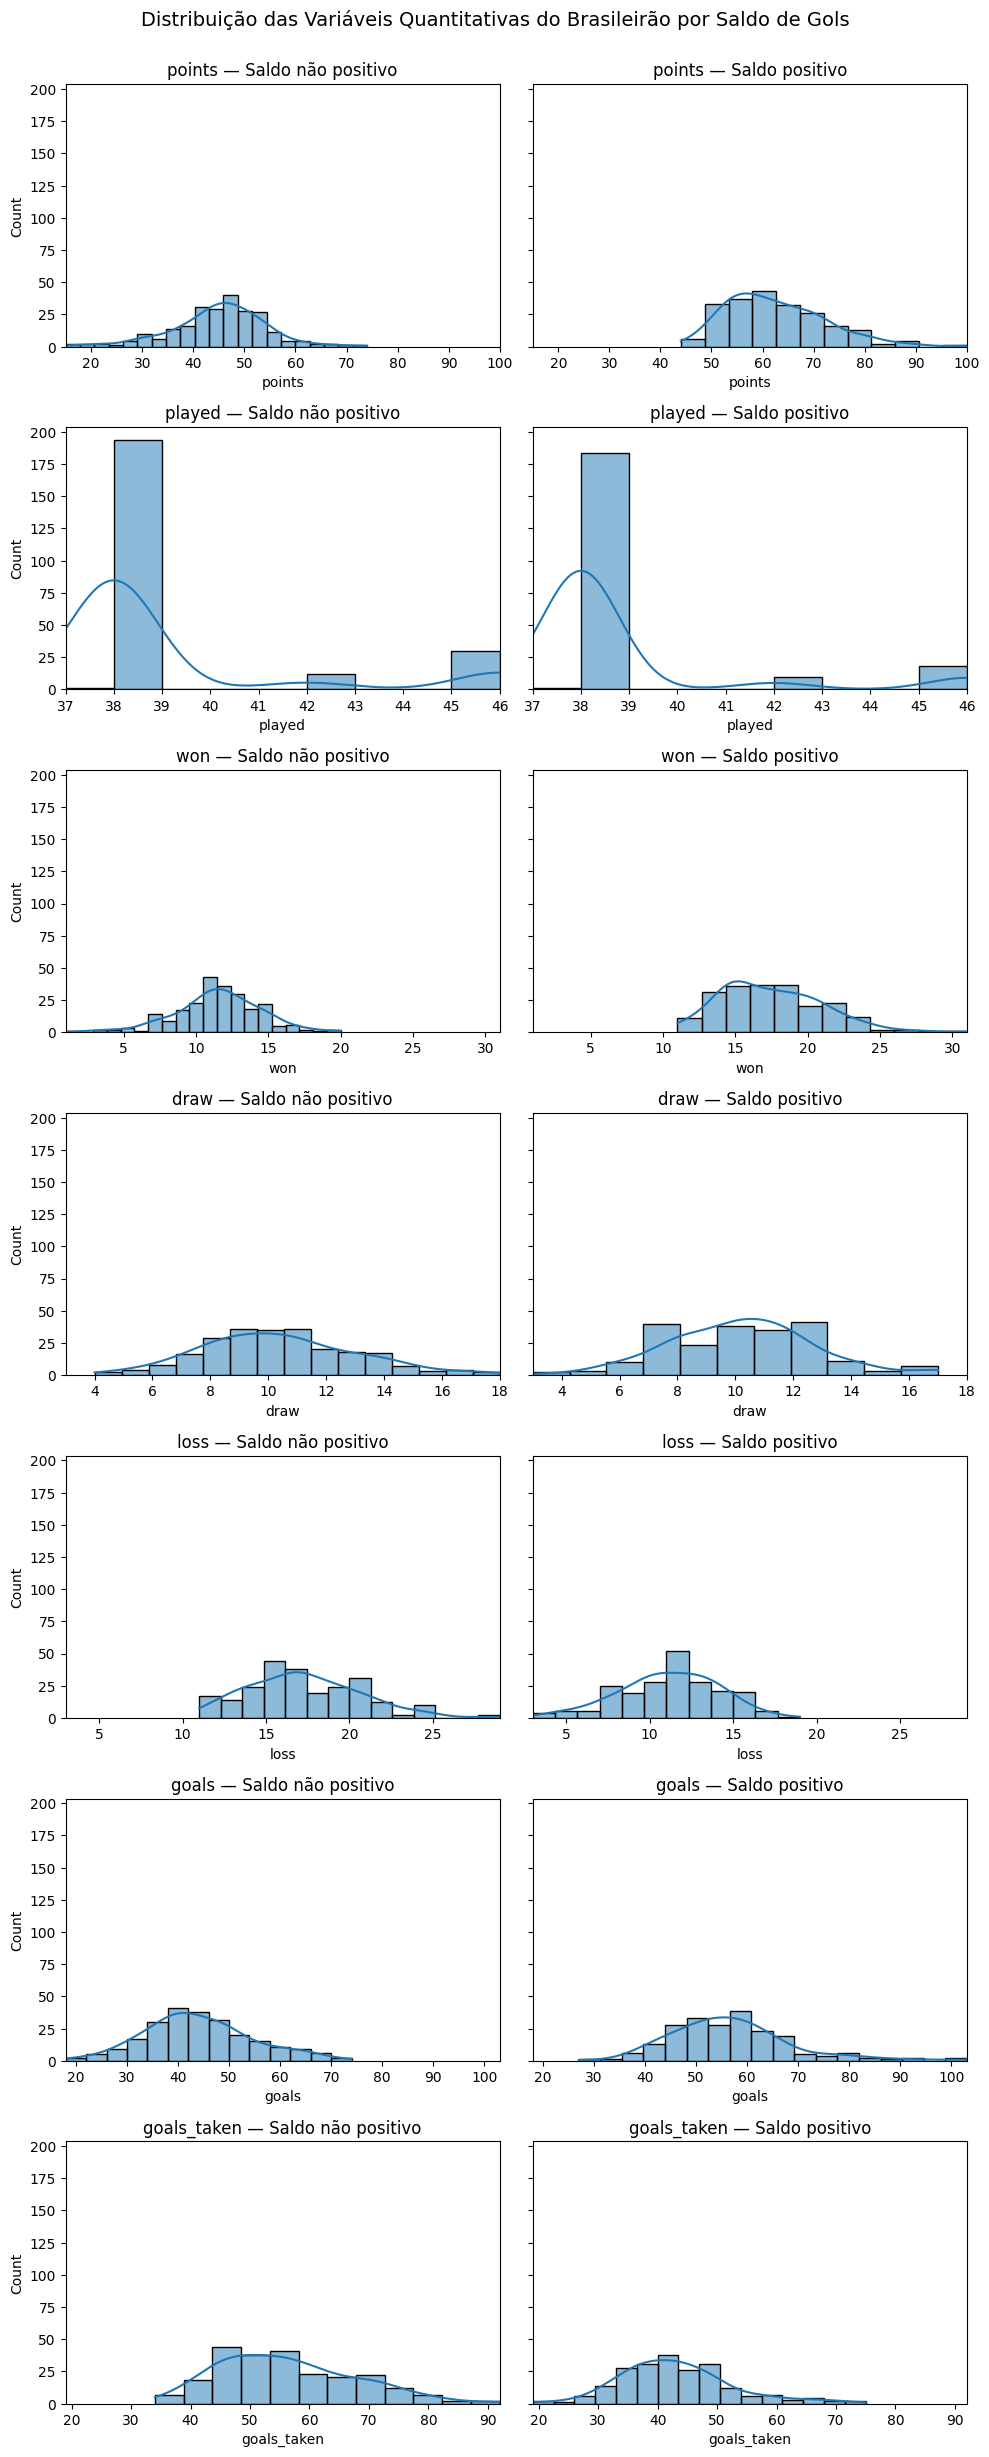

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np


df["saldo_resultado"] = np.where(
    df["goals_diff"] > 0,
    "Saldo positivo",
    "Saldo não positivo"
)


VARS_COMPARAR = [
    "points",
    "played",
    "won",
    "draw",
    "loss",
    "goals",
    "goals_taken"
]

fig, axes = plt.subplots(
    len(VARS_COMPARAR),
    2,
    figsize=(10, 3.5 * len(VARS_COMPARAR)),
    sharey=True
)

for i, col in enumerate(VARS_COMPARAR):

    lim = (df[col].min(), df[col].max())

    for j, classe in enumerate(["Saldo não positivo", "Saldo positivo"]):

        subset = df[df["saldo_resultado"] == classe]

        sns.histplot(
            data=subset,
            x=col,
            kde=True,
            ax=axes[i, j]
        )

        axes[i, j].set_xlim(lim)
        axes[i, j].set_title(f"{col} — {classe}")

fig.suptitle(
    "Distribuição das Variáveis Quantitativas do Brasileirão por Saldo de Gols",
    fontsize=14,
    y=1.001
)

plt.tight_layout()
plt.show()

 As variáveis points, won, loss, goals e goals_taken apresentam formatos claramente diferentes entre os grupos. Equipes com saldo positivo tendem a ter mais pontos, vitórias e gols marcados, enquanto equipes com saldo não positivo tendem a apresentar mais derrotas e gols sofridos. Já draw e played apresentam distribuições mais semelhantes entre as classes.

#### Testes de Aderência

Será que a pontuação dos clubes (points) segue uma distribuição normal?

O **Shapiro-Wilk** como o teste de aderência mais usado pra normalidade, junto com o **QQ-Plot** como visualização de apoio. Vamos testar com `chol`.

Shapiro-Wilk - points: estatística=0.9931, p-valor=0.0379
Rejeita H0 (normalidade)? Sim (alpha = 0.05)


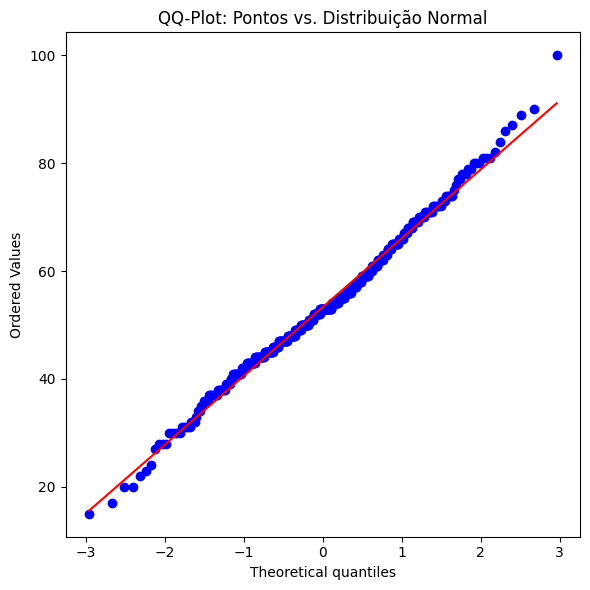

In [ ]:
from scipy import stats
import matplotlib.pyplot as plt

stat_sw, p_valor_sw = stats.shapiro(df["points"].dropna())

print(f"Shapiro-Wilk - points: estatística={stat_sw:.4f}, p-valor={p_valor_sw:.4f}")

print(
    "Rejeita H0 (normalidade)?",
    "Sim" if p_valor_sw < 0.05 else "Não",
    "(alpha = 0.05)"
)

# QQ-Plot
fig, ax = plt.subplots(figsize=(6, 6))

stats.probplot(df["points"].dropna(), dist="norm", plot=ax)

ax.set_title("QQ-Plot: Pontos vs. Distribuição Normal")

plt.tight_layout()
plt.show()

**Como ler:** se os pontos (roxo) seguissem a reta vermelha de perto, a variável seguiria uma normal. Pontos que se afastam da reta nas pontas indicam cauda mais pesada ou mais leve que a normal — coerente com o resultado do Shapiro-Wilk acima.

**Nota: cuidado com duas armadilhas de interpretação**

- **Tamanho da amostra e poder do teste:** é comum achar que "poucos dados" tornam mais fácil rejeitar a normalidade e é o contrário. Amostras **pequenas** têm **menos poder estatístico**, ou seja, tendem a *não* rejeitar mesmo quando os dados realmente não são normais. Já amostras **muito grandes** (milhares de linhas) deixam o teste sensível demais, rejeitando por desvios triviais. Com n≈303 (nem pequeno, nem enorme) e três evidências concordando — skewness alto, QQ-Plot afastado da reta, e Shapiro-Wilk rejeitando — o resultado é razoavelmente confiável, não um artefato do tamanho da amostra.
- **Como afirmar o resultado:** quando o teste **rejeita** H0 (nosso caso, p < 0.05), a afirmação correta é "temos evidência estatística **contra** a normalidade" que é uma conclusão forte. A frase "não podemos garantir normalidade" cabe no caso oposto: quando o teste **não rejeita** H0, já que a ausência de rejeição nunca prova que os dados são normais, só que não há evidência suficiente contra.

O teste de Shapiro-Wilk apresentou p-valor inferior a 0,05, portanto rejeitamos a hipótese nula de normalidade para a variável points. Assim, há evidência estatística de que a pontuação dos clubes não segue exatamente uma distribuição normal.

Entretanto, o QQ-Plot mostra que a maior parte dos pontos permanece próxima da reta teórica, indicando que a distribuição é aproximadamente normal na região central. Os principais desvios aparecem nas extremidades, correspondendo a campanhas com pontuações muito baixas ou muito altas.

Dessa forma, apesar de a distribuição de pontos apresentar comportamento próximo ao normal visualmente, o teste de Shapiro-Wilk identifica desvios suficientes para rejeitar a normalidade ao nível de significância de 5%.

In [ ]:
resultados_shapiro = []

for col in VARS_QUANT:
    stat, p = stats.shapiro(df[col].dropna())

    resultados_shapiro.append({
        "variavel": col,
        "estatistica": round(stat, 4),
        "p_valor": round(p, 6),
        "resultado": "Não normal" if p < 0.05 else "Não rejeita normalidade"
    })

pd.DataFrame(resultados_shapiro).set_index("variavel")

,estatistica,p_valor,resultado
variavel,,,
points,0.9931,0.037897,Não normal
played,0.4451,0.000000,Não normal
won,0.9861,0.000265,Não normal
draw,0.9794,0.000005,Não normal
loss,0.9926,0.024645,Não normal
goals,0.9782,0.000003,Não normal
goals_taken,0.9737,0.000000,Não normal
goals_diff,0.9963,0.381839,Não rejeita normalidade


**ECDF — outra forma de ver a distribuição**

Diferente do histograma, a ECDF não depende de escolher o número de bins: para cada valor no eixo X, a curva mostra a **proporção acumulada** de observações menores ou iguais àquele valor. É especialmente útil pra comparar duas distribuições lado a lado — onde as curvas se distanciam mais é onde a diferença entre os grupos é mais perceptível.

Vamos ilustrar com uma única variável (`chol`, colesterol), só pra fixar como essa visualização se lê.

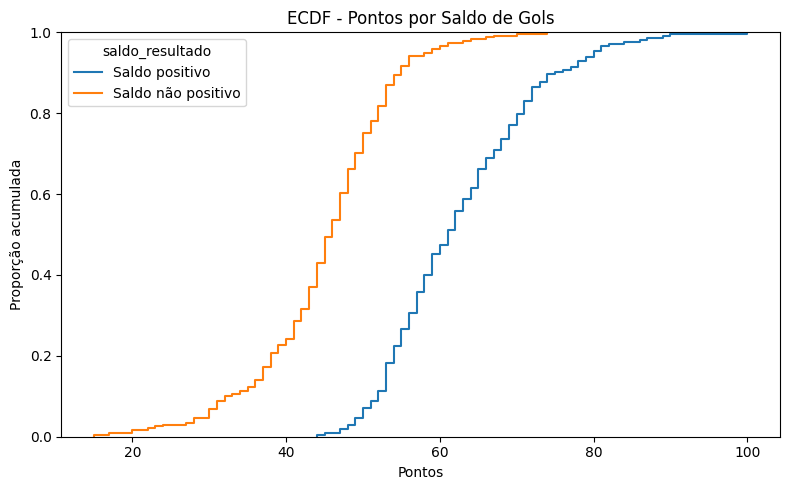

In [ ]:
plt.figure(figsize=(8, 5))

sns.ecdfplot(
    data=df,
    x="points",
    hue="saldo_resultado"
)

plt.title("ECDF - Pontos por Saldo de Gols")
plt.xlabel("Pontos")
plt.ylabel("Proporção acumulada")
plt.tight_layout()
plt.show()

Como ler: em qualquer valor do eixo X, a altura da curva indica qual proporção das equipes daquele grupo terminou a temporada com pontuação menor ou igual àquele valor. Quanto mais separadas as curvas estiverem, maior é a diferença entre as distribuições dos dois grupos.

No gráfico, as equipes com saldo de gols não positivo estão concentradas em pontuações menores, enquanto as equipes com saldo positivo apresentam pontuações mais elevadas. A separação entre as curvas é bastante clara principalmente na faixa intermediária de pontos, indicando uma forte diferença de desempenho entre os grupos.

### Métricas de Tendêncial Central

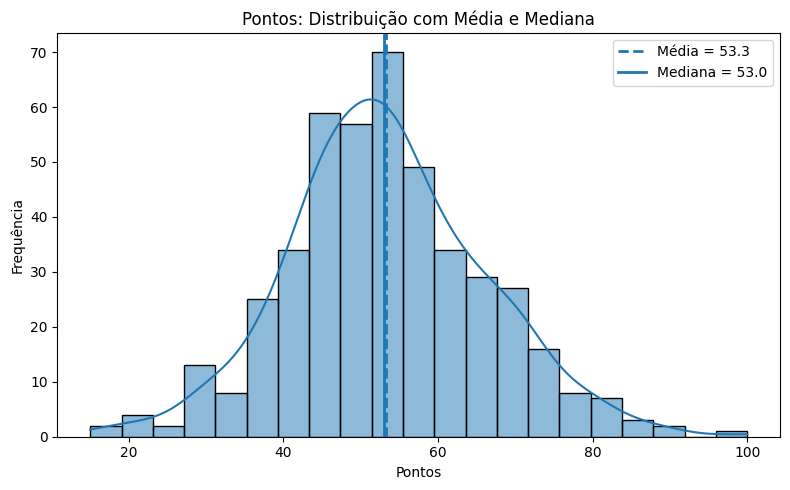

In [ ]:
media_points = df["points"].mean()
mediana_points = df["points"].median()

plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="points",
    kde=True
)

plt.axvline(
    media_points,
    linestyle="--",
    linewidth=2,
    label=f"Média = {media_points:.1f}"
)

plt.axvline(
    mediana_points,
    linestyle="-",
    linewidth=2,
    label=f"Mediana = {mediana_points:.1f}"
)

plt.title("Pontos: Distribuição com Média e Mediana")
plt.xlabel("Pontos")
plt.ylabel("Frequência")
plt.legend()

plt.tight_layout()
plt.show()

### Dispersão

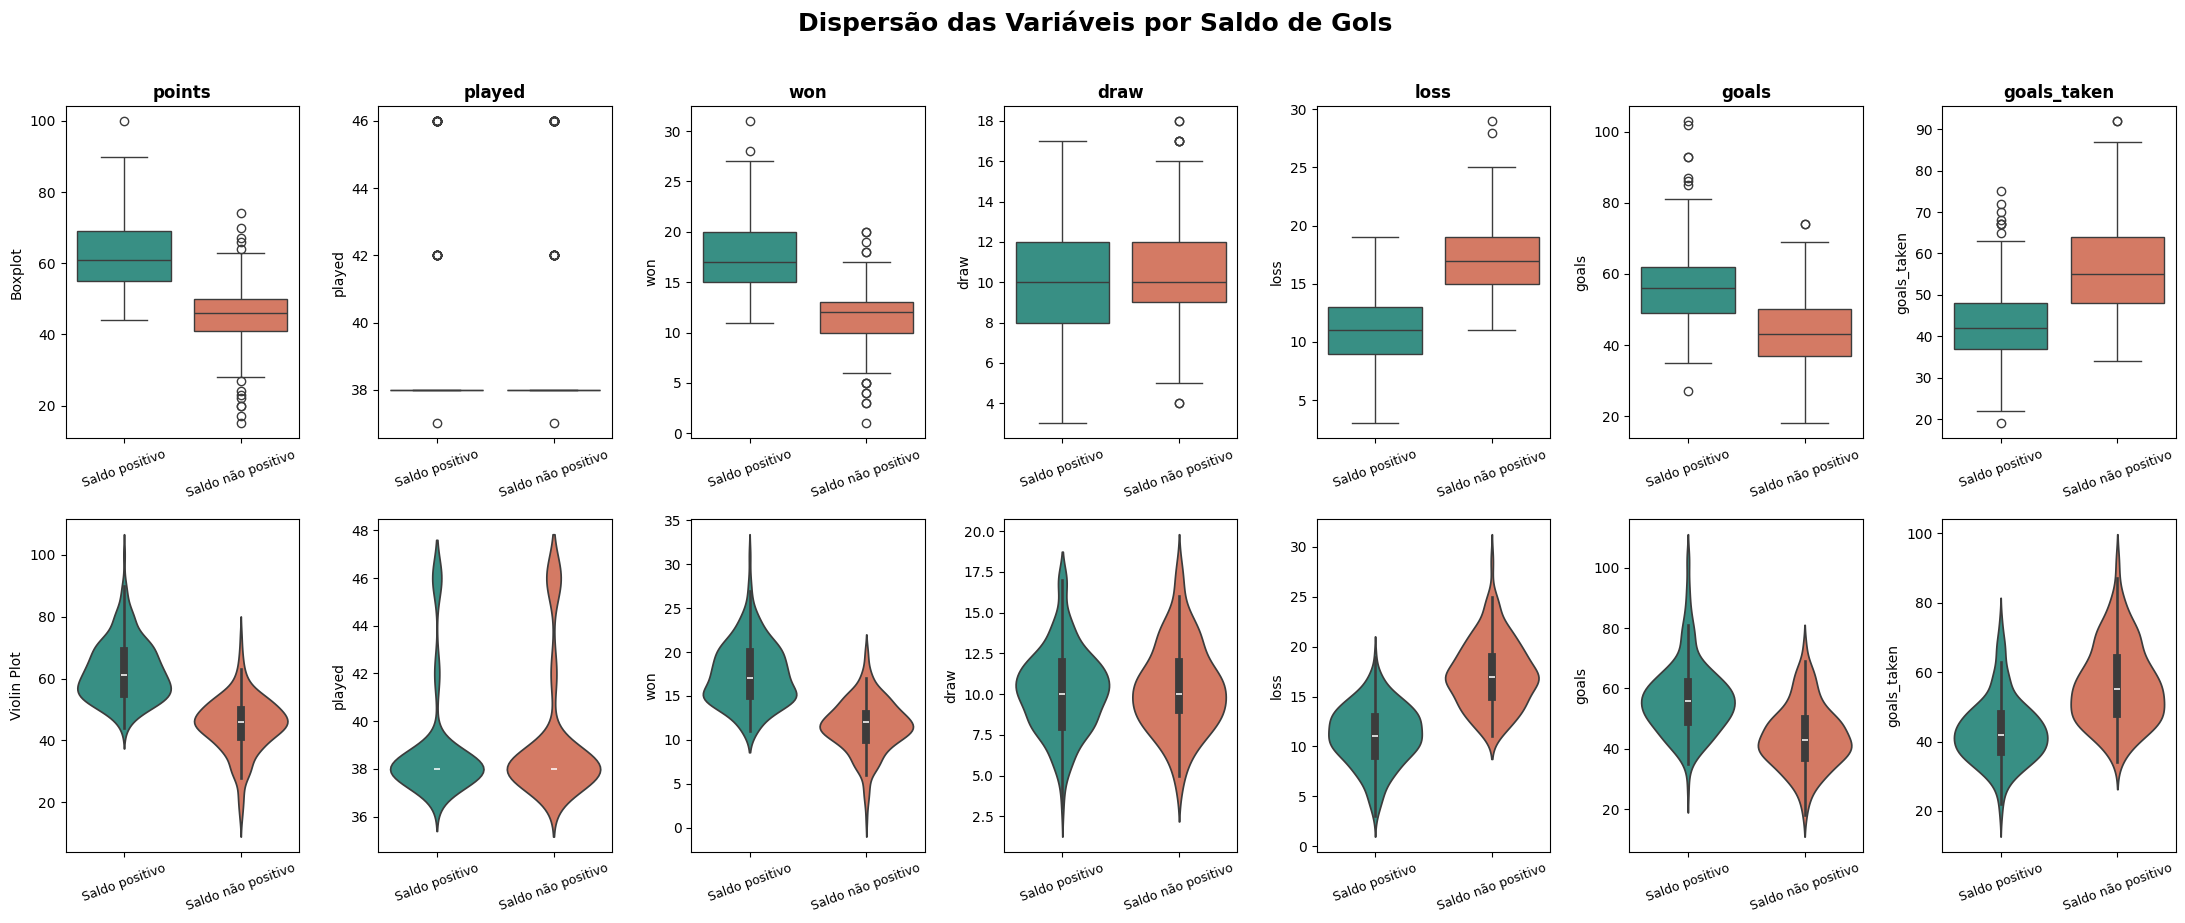

In [ ]:
dispersao = df[VARS_QUANT].agg(["var", "std"]).T



dispersao["IQR"] = df[VARS_QUANT].quantile(0.75) - df[VARS_QUANT].quantile(0.25)



dispersao.round(2)
palette_classe = {
    "Saldo não positivo": "#E76F51",
    "Saldo positivo": "#2A9D8F"
}

fig, axes = plt.subplots(
    2,
    len(VARS_COMPARAR),
    figsize=(22, 9)
)

for i, col in enumerate(VARS_COMPARAR):

    # BOXPLOT
    sns.boxplot(
        data=df,
        x="saldo_resultado",
        y=col,
        hue="saldo_resultado",
        palette=palette_classe,
        legend=False,
        ax=axes[0, i]
    )

    axes[0, i].set_title(
        col,
        fontsize=12,
        fontweight="bold"
    )

    axes[0, i].set_xlabel("")
    axes[0, i].tick_params(
        axis="x",
        rotation=20,
        labelsize=9
    )


    sns.violinplot(
        data=df,
        x="saldo_resultado",
        y=col,
        hue="saldo_resultado",
        palette=palette_classe,
        legend=False,
        ax=axes[1, i]
    )

    axes[1, i].set_xlabel("")
    axes[1, i].tick_params(
        axis="x",
        rotation=20,
        labelsize=9
    )

axes[0, 0].set_ylabel("Boxplot")
axes[1, 0].set_ylabel("Violin Plot")

fig.suptitle(
    "Dispersão das Variáveis por Saldo de Gols",
    fontsize=18,
    fontweight="bold",
    y=1.02
)

plt.tight_layout()
plt.show()

**Pra discutir:** points, won, loss, goals e goals_taken apresentam diferenças claras entre as campanhas com saldo positivo e saldo não positivo. As equipes com saldo positivo tendem a ter medianas maiores de pontos, vitórias e gols marcados, enquanto apresentam medianas menores de derrotas e gols sofridos.

A variável draw apresenta bastante sobreposição entre os dois grupos, indicando menor capacidade de diferenciá-los. Já played praticamente não separa as classes, pois a maior parte das equipes disputou a mesma quantidade de partidas em cada formato do campeonato.

## 4. Tratamento de Dados Ausentes e Outliers

Agora que já vimos o retrato estatístico "antes" (Seção 3), temos a informação que faltava pra decidir como tratar tanto os dados ausentes (`ca`, `thal`) quanto os outliers das variáveis quantitativas. Depois do tratamento, vamos rodar a estatística descritiva mais uma vez ("depois") pra confirmar o efeito das escolhas e fechar o ciclo iterativo que começamos lá na abertura.

### Detecção de Outliers por IQR

A regra clássica marca como outlier qualquer ponto fora de `[Q1 - 1.5*IQR, Q3 + 1.5*IQR]`.

In [ ]:
def limites_iqr(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1

    return q1 - 1.5 * iqr, q3 + 1.5 * iqr


resumo_outliers = {}

for col in VARS_QUANT:

    lim_inf, lim_sup = limites_iqr(df[col])

    n_outliers = (
        (df[col] < lim_inf) |
        (df[col] > lim_sup)
    ).sum()

    resumo_outliers[col] = {
        "limite_inferior": round(lim_inf, 2),
        "limite_superior": round(lim_sup, 2),
        "n_outliers": n_outliers
    }

pd.DataFrame(resumo_outliers).T

,limite_inferior,limite_superior,n_outliers
points,21.00,85.00,9.0
played,38.00,38.00,72.0
won,2.00,26.00,4.0
draw,2.00,18.00,0.0
loss,2.00,26.00,2.0
goals,15.50,83.50,7.0
goals_taken,15.50,83.50,4.0
goals_diff,-41.12,41.88,6.0


### Visualizando os Outliers

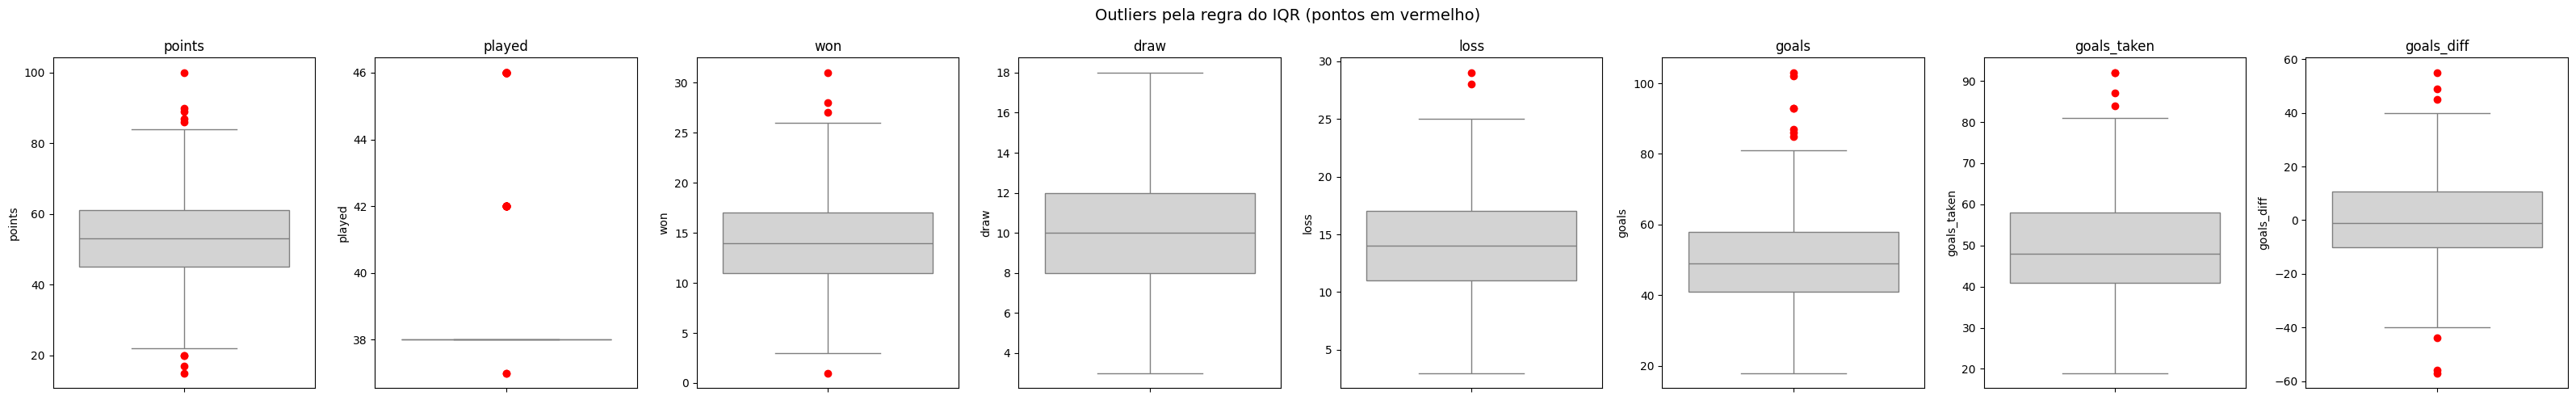

In [ ]:
fig, axes = plt.subplots(
    1,
    len(VARS_QUANT),
    figsize=(4 * len(VARS_QUANT), 5)
)

for i, col in enumerate(VARS_QUANT):

    sns.boxplot(
        data=df,
        y=col,
        ax=axes[i],
        color="lightgray",
        flierprops=dict(
            markerfacecolor="red",
            markeredgecolor="red",
            marker="o"
        )
    )

    axes[i].set_title(col)

fig.suptitle(
    "Outliers pela regra do IQR (pontos em vermelho)",
    fontsize=14
)

plt.tight_layout()
plt.show()

**Pra discutir:** o slide 26 da aula 9 classifica outliers em três tipos, cada um com um tratamento recomendado:

| Tipo | Cenário | O que fazer? |
|---|---|---|
| Estatístico | Legítimo | Manter / Transformar |
| De domínio | Viola regra de negócio ou condições físicas | Investigar! |
| Erros de dados | Falhas | Corrigir se possível / Remover como última opção |

Olhando os outliers encontrados (principalmente em `chol` e `oldpeak`): eles parecem fisiologicamente plausíveis (pacientes reais podem ter colesterol muito alto), ou parecem violar algum limite físico conhecido? Isso muda qual das três categorias se aplica — e, consequentemente, se devemos manter, transformar ou remover.
A regra do IQR identificou valores extremos em diversas variáveis, como points, played, won, loss, goals, goals_taken e goals_diff. Entretanto, esses valores parecem ser, em sua maioria, outliers legítimos, pois representam campanhas reais com desempenhos excepcionalmente altos ou baixos.

A variável played merece atenção especial. Os valores 37, 42 e 46 aparecem como outliers porque a maioria das observações está concentrada em 38 partidas. Entretanto, isso pode ser explicado pelas mudanças no formato do Campeonato Brasileiro ao longo das temporadas, não indicando necessariamente um erro.

Da mesma forma, valores extremos de pontos, vitórias, derrotas, gols marcados, gols sofridos e saldo de gols podem representar equipes com campanhas excepcionalmente boas ou ruins.

Portanto, não há motivo para remover automaticamente esses registros. Eles serão mantidos, pois fazem parte da variabilidade natural do campeonato e podem conter informações importantes para a análise.
No meu dataset, eu não removeria esses registros apenas pelo IQR. O correto seria remover somente se você descobrisse, por exemplo, que um time aparece com 300 gols, 120 partidas ou algum outro valor impossível/incompatível com a temporada

### Decidindo o Tratamento dos Dados Ausentes

Reunindo o que já discutimos: o mecanismo mais provável para `ca`/`thal` é MAR ou MCAR (não MNAR), e o volume é pequeno (poucas linhas em ~300). Com essas duas informações juntas, a decisão pragmática é remover as linhas afetadas — o risco de viés é baixo (mecanismo provavelmente não depende do próprio valor ausente) e o custo de perder ~2% das linhas é pequeno.

In [ ]:
linhas_antes = df.shape[0]

total_ausentes = df.isna().sum().sum()

linhas_depois = df.shape[0]

print(f"Total de valores ausentes: {total_ausentes}")
print(f"Linhas antes: {linhas_antes}")
print(f"Linhas depois: {linhas_depois}")
print(f"Linhas removidas: {linhas_antes - linhas_depois}")

Total de valores ausentes: 0
Linhas antes: 450
Linhas depois: 450
Linhas removidas: 0


### Decidindo o Tratamento dos Outliers

Diferente dos ausentes, aqui **não vamos remover automaticamente**. Pelos valores encontrados (dentro de faixas clinicamente plausíveis, ainda que raras), a classificação mais provável é **"Estatístico"**, outliers legítimos, não erros de coleta. Sendo assim, o tratamento recomendado nesse caso é **manter** (a informação é real e pode ser clinicamente relevante — por exemplo, exatamente os pacientes com colesterol mais extremo podem ser os de maior risco) ou, se for necessário para alguma técnica estatística específica mais à frente (ex: métodos sensíveis à assimetria), **transformar**.

Vamos manter os valores originais por enquanto, mas ilustrar como ficaria uma transformação logarítmica em `chol` — útil caso, mais adiante em análises futuras, a assimetria atrapalhe algum teste ou modelo.

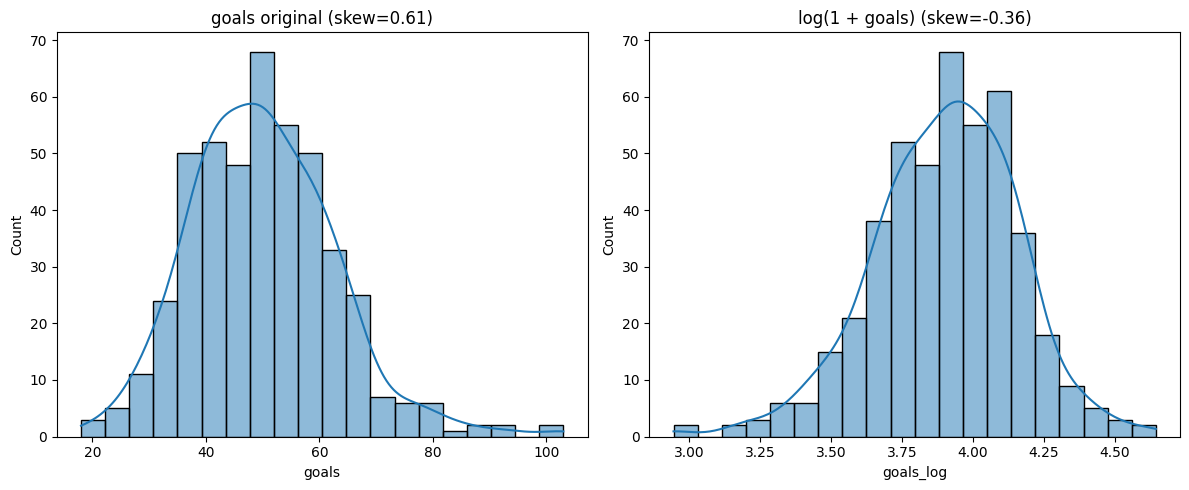

In [ ]:
df["goals_log"] = np.log1p(df["goals"])

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.histplot(
    data=df,
    x="goals",
    kde=True,
    ax=axes[0]
)

axes[0].set_title(
    f"goals original (skew={df['goals'].skew():.2f})"
)

sns.histplot(
    data=df,
    x="goals_log",
    kde=True,
    ax=axes[1]
)

axes[1].set_title(
    f"log(1 + goals) (skew={df['goals_log'].skew():.2f})"
)

plt.tight_layout()
plt.show()

**Pra discutir:** a transformação logarítmica reduziu visivelmente a assimetria? Mantivemos `chol_log` só como demonstração, mas não vamos usá-la nas próximas seções. A ideia foi mostrar como opção se fosse o objetivo de, por exemplo, alimentar um teste paramétrico que exige normalidade.

**Nota para quando vocês replicarem no dataset de vocês:** nem todo outlier deve ser removido. Antes de decidir, classifiquem: é um valor estatisticamente raro mas plausível (manter/transformar), viola alguma regra física ou de negócio (investigar antes de decidir), ou é claramente um erro de digitação/coleta (corrigir ou remover)?

Discussão: A transformação logarítmica reduziu a assimetria da variável goals, fazendo o skewness passar de 0,61 para -0,36. Isso indica que a distribuição ficou mais próxima da simetria, embora tenha passado a apresentar uma leve assimetria à esquerda.

Apesar dessa melhora, a variável original já apresentava apenas uma assimetria moderada. Além disso, os valores mais altos de gols podem representar campanhas reais e excepcionais, e não erros de coleta. Por isso, a transformação foi utilizada apenas como demonstração e a variável goals original será mantida nas próximas análises.
Os outliers encontrados foram classificados principalmente como valores legítimos, pois representam campanhas excepcionalmente boas ou ruins. Valores extremos de points, won, goals, goals_taken e goals_diff podem ocorrer naturalmente no futebol. Já os valores extremos de played estão relacionados, em grande parte, às mudanças no formato do Campeonato Brasileiro entre temporadas. Portanto, não foram identificados motivos suficientes para remover esses registros.

## 5. Estatística Descritiva pt 2

Fechando o ciclo iterativo: tratamos os ausentes e decidimos manter os outliers. Agora rodamos a mesma bateria de estatísticas da Seção 3 para comparar diretamente com o "antes".

In [ ]:
desc_depois = df[VARS_QUANT].describe().T

desc_depois["skewness"] = df[VARS_QUANT].skew()
desc_depois["kurtosis"] = df[VARS_QUANT].kurtosis()

(
    desc_depois[["mean", "50%", "std", "min", "max", "skewness", "kurtosis"]]
    .rename(columns={"50%": "median"})
    .round(2)
    .style.format(precision=2)
    .background_gradient(
        cmap="Blues",
        subset=["skewness", "kurtosis"]
    )
)

,mean,median,std,min,max,skewness,kurtosis
points,53.33,53.00,12.75,15.00,100.00,0.19,0.45
played,39.04,38.00,2.56,37.00,46.00,2.18,3.03
won,14.36,14.00,4.38,1.00,31.00,0.32,0.38
draw,10.32,10.00,2.62,3.00,18.00,0.30,0.19
loss,14.37,14.00,4.40,3.00,29.00,0.18,-0.06
goals,50.03,49.00,12.79,18.00,103.00,0.61,1.21
goals_taken,50.04,48.00,12.45,19.00,92.00,0.60,0.15
goals_diff,-0.01,-1.00,16.61,-57.00,55.00,0.01,0.47


### Comparando "antes"x "depois""



In [ ]:
comparacao = pd.DataFrame({
    "skewness_antes": desc["skewness"],
    "skewness_depois": desc_depois["skewness"],
    "kurtosis_antes": desc["kurtosis"],
    "kurtosis_depois": desc_depois["kurtosis"],
})

comparacao["delta_skewness"] = (
    comparacao["skewness_depois"] - comparacao["skewness_antes"]
).round(3)

comparacao["delta_kurtosis"] = (
    comparacao["kurtosis_depois"] - comparacao["kurtosis_antes"]
).round(3)

comparacao.round(3)

,skewness_antes,skewness_depois,kurtosis_antes,kurtosis_depois,delta_skewness,delta_kurtosis
points,0.190,0.190,0.449,0.449,0.0,0.0
played,2.178,2.178,3.028,3.028,0.0,0.0
won,0.317,0.317,0.385,0.385,0.0,0.0
draw,0.298,0.298,0.192,0.192,0.0,0.0
loss,0.175,0.175,-0.059,-0.059,0.0,0.0
goals,0.607,0.607,1.209,1.209,0.0,0.0
goals_taken,0.595,0.595,0.145,0.145,0.0,0.0
goals_diff,0.009,0.009,0.465,0.465,0.0,0.0


**Pra discutir:** Os valores mudaram muito? Não. Como não removemos registros nem transformamos as variáveis usadas na análise principal, era esperado que skewness e kurtosis permanecessem praticamente iguais. Isso confirma que o tratamento foi conservador e que os outliers encontrados foram considerados plausíveis no contexto do futebol.

**O colesterol ainda rejeita normalidade?**

Vamos rodar o mesmo Shapiro-Wilk da Seção 3, agora nos dados tratados.

In [ ]:
from scipy import stats

stat_sw_depois, p_valor_sw_depois = stats.shapiro(
    df["points"].dropna()
)

print(
    f"Shapiro-Wilk (depois) - points: "
    f"estatística={stat_sw_depois:.4f}, "
    f"p-valor={p_valor_sw_depois:.4f}"
)

print(
    "Rejeita H0 (normalidade)?",
    "Sim" if p_valor_sw_depois < 0.05 else "Não",
    "(alpha = 0.05)"
)

Shapiro-Wilk (depois) - points: estatística=0.9931, p-valor=0.0379
Rejeita H0 (normalidade)? Sim (alpha = 0.05)


**Visualizando antes x depois, lado a lado**

Vamos sobrepor as distribuições de duas variáveis que mais chamaram atenção na Seção 4 (`chol` e `oldpeak`), comparando a versão original (`df_antes`) com a tratada (`df`).

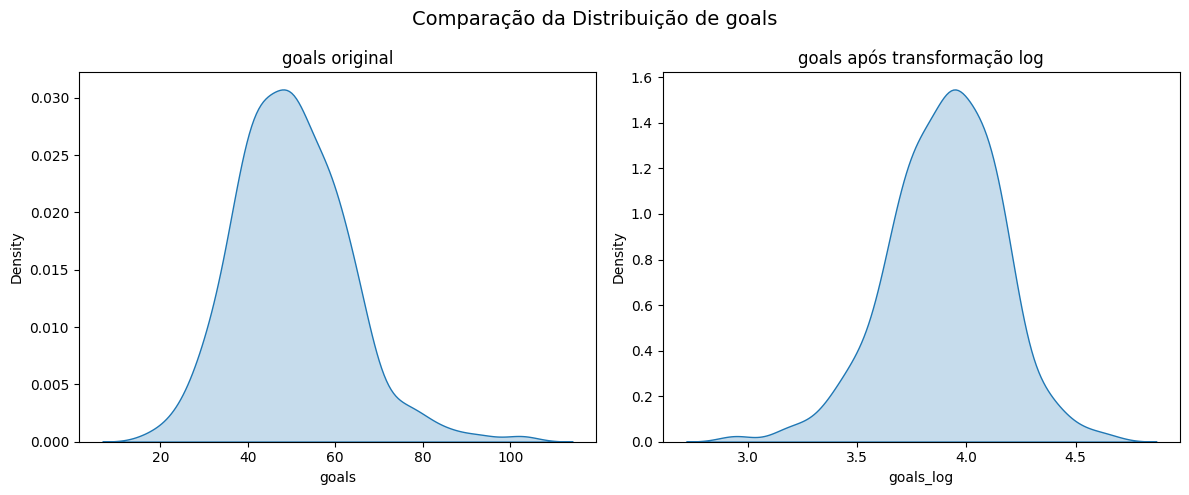

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df["goals_log"] = np.log1p(df["goals"])

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.kdeplot(data=df, x="goals", fill=True, ax=axes[0])
axes[0].set_title("goals original")

sns.kdeplot(data=df, x="goals_log", fill=True, ax=axes[1])
axes[1].set_title("goals após transformação log")

fig.suptitle("Comparação da Distribuição de goals", fontsize=14)

plt.tight_layout()
plt.show()

**Pra discutir:** as curvas "antes" e "depois" praticamente se sobrepõem? Isso é o esperado aqui, já que removemos poucas linhas e não tocamos nos outliers.

A transformação logarítmica alterou a distribuição de goals, reduzindo a assimetria positiva observada na variável original. A distribuição transformada ficou mais concentrada e mais próxima da simetria, embora tenha passado a apresentar uma leve assimetria negativa.

Mesmo assim, optamos por não utilizar goals_log nas análises principais, pois a variável original já apresentava apenas assimetria moderada e os valores extremos representam campanhas reais, não erros de dados.

Dessa forma, a transformação foi mantida apenas como demonstração de uma possível técnica de tratamento.

## 6. Princípio Relacional

### Análise de Variáveis Qualitativas

Agora focaremos na avaliação de frequência e desbalanceamento das variáveis qualitativas.




#### Frequências absolutas e relativas

In [ ]:
for col in VARS_QUALI:
    freq_abs = df[col].value_counts()
    freq_rel = df[col].value_counts(normalize=True).round(3)

    print(f"\n--- {col} ---")
    print(
        pd.concat(
            [
                freq_abs.rename("absoluta"),
                freq_rel.rename("relativa")
            ],
            axis=1
        )
    )


--- team ---
                      absoluta  relativa
team                                    
São Paulo                   22     0.049
Flamengo                    22     0.049
Fluminense                  22     0.049
Atlético Mineiro            21     0.047
Internacional               21     0.047
Athletico Paranaense        21     0.047
Corinthians                 21     0.047
Santos                      21     0.047
Grêmio                      20     0.044
Palmeiras                   20     0.044
Cruzeiro                    19     0.042
Botafogo                    19     0.042
Vasco                       17     0.038
Coritiba                    15     0.033
Goiás                       15     0.033
Bahia                       12     0.027
Sport                       11     0.024
Vitória                     11     0.024
Figueirense                 11     0.024
Fortaleza                    9     0.020
Ponte Preta                  9     0.020
Juventude                    8     0.018
At

#### Visualizando as frequências

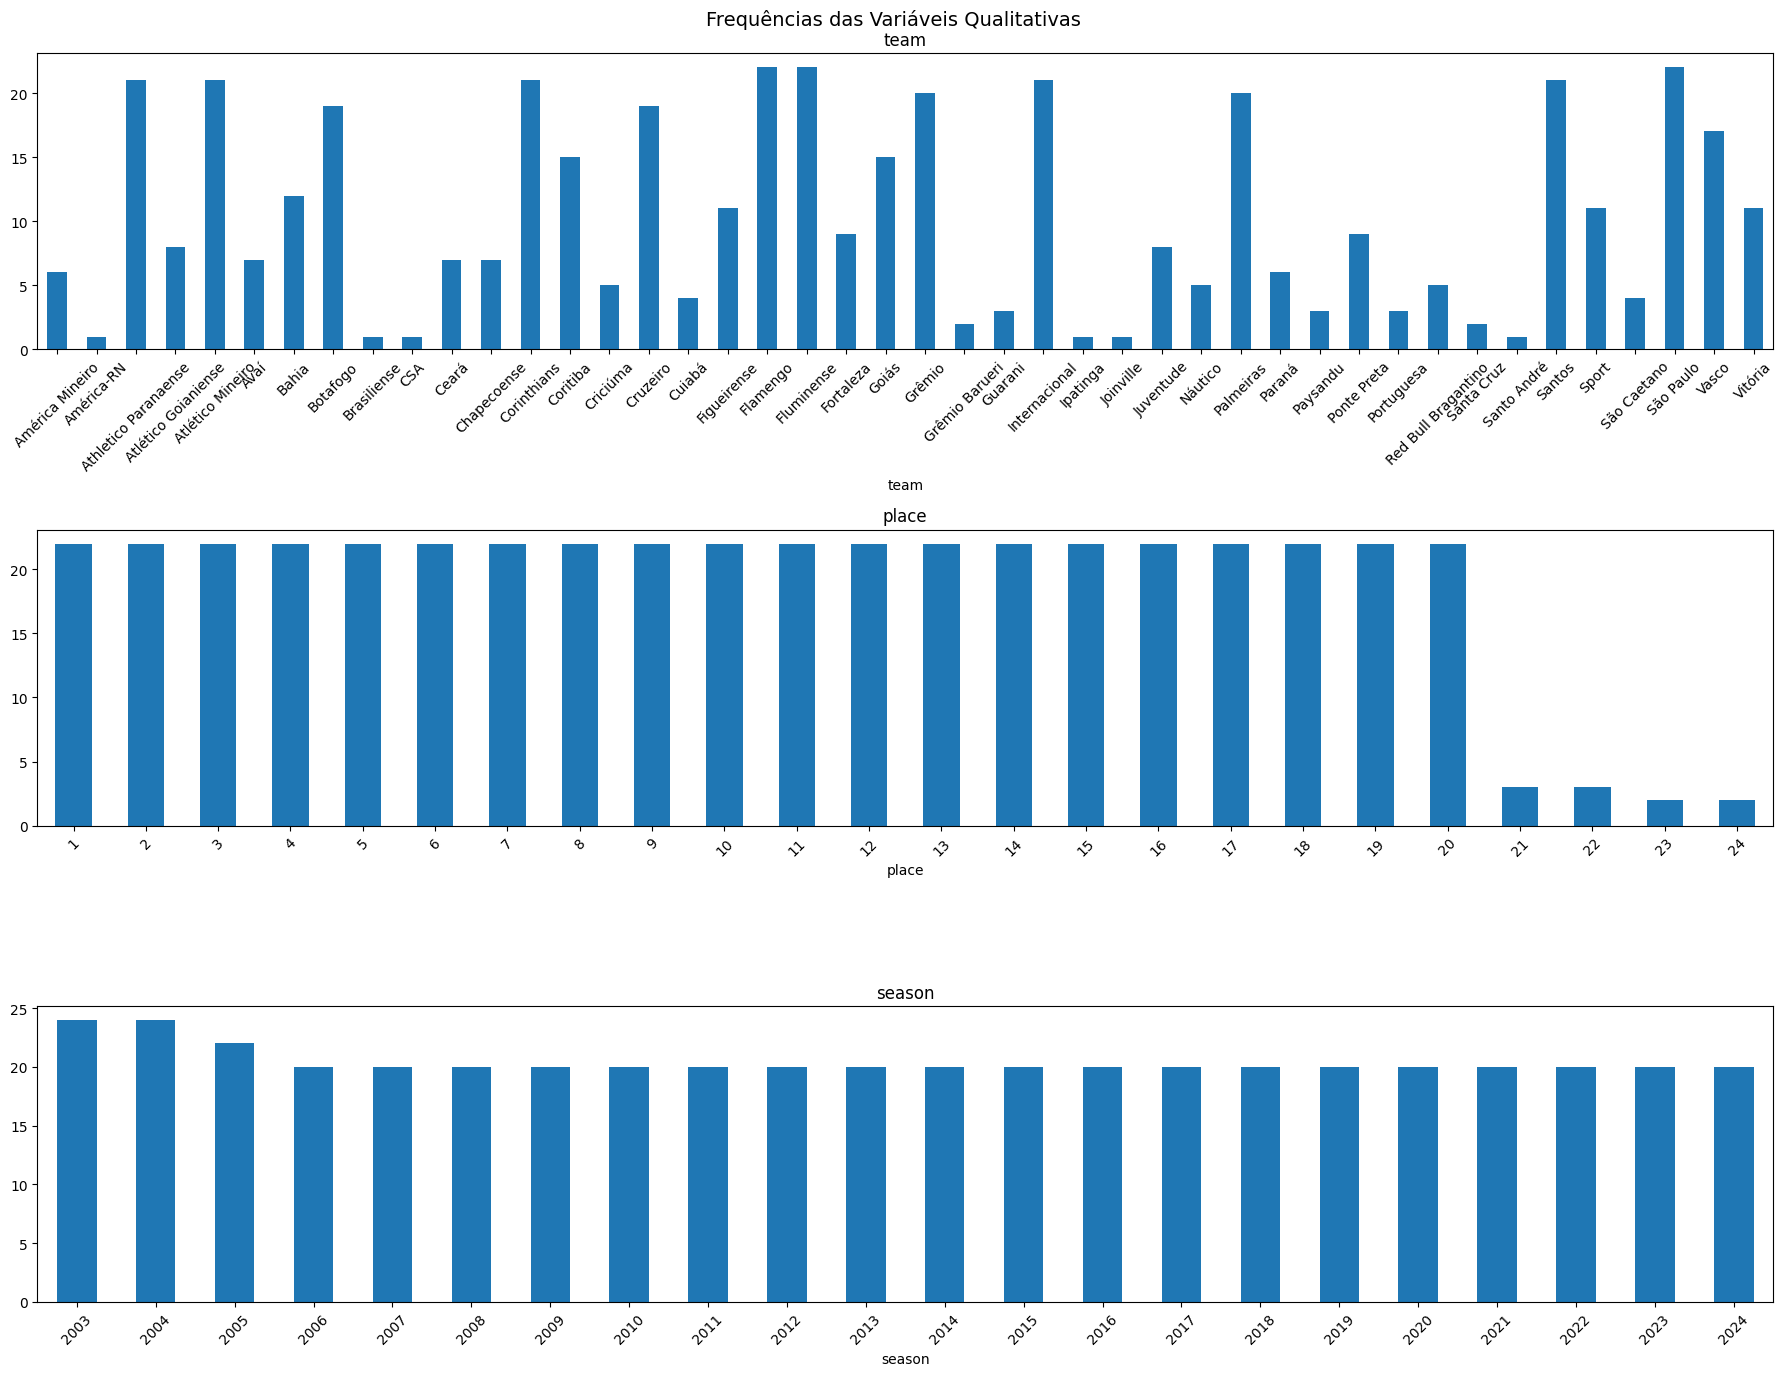

In [ ]:
fig, axes = plt.subplots(3, 1, figsize=(18, 14))

for i, col in enumerate(VARS_QUALI):
    df[col].value_counts().sort_index().plot(
        kind="bar",
        ax=axes[i]
    )

    axes[i].set_title(col)
    axes[i].tick_params(axis="x", rotation=45)

fig.suptitle(
    "Frequências das Variáveis Qualitativas",
    fontsize=14
)

plt.tight_layout()
plt.show()

**Pra discutir:** Não há uma variável qualitativa em que uma única categoria domine quase todas as observações.

A variável team apresenta diferenças de frequência, pois alguns clubes participaram de mais temporadas do Campeonato Brasileiro do que outros. Já place é bastante equilibrada entre as posições 1 e 20, enquanto as posições 21 a 24 aparecem com menor frequência por estarem presentes apenas em temporadas com maior número de participantes.

A variável season também apresenta distribuição relativamente equilibrada, com pequenas diferenças nas primeiras temporadas devido às mudanças no número de clubes participantes.

Portanto, o principal desbalanceamento ocorre em team, mas ele é esperado e representa a participação histórica diferente dos clubes, e não um problema de qualidade dos dados.

#### Desbalanceamento entre Classes

- **Razão de desbalanceamento** — # classe majoritária / # classe minoritária (quanto maior, mais desbalanceado).
- **Entropia de Shannon normalizada** — 1 = perfeitamente balanceado, 0 = uma classe domina tudo.

Vamos aplicar as duas em todas as qualitativas, incluindo o próprio alvo `doenca_cardiaca`.

In [ ]:
from scipy.stats import entropy
import numpy as np
import pandas as pd
import numpy as np

df["saldo_resultado"] = np.where(
    df["goals_diff"] > 0,
    "Saldo positivo",
    "Saldo não positivo"
)

def metrica_desbalanceamento(serie):
    contagens = serie.value_counts()

    razao = contagens.max() / contagens.min()

    props = contagens / contagens.sum()
    n_classes = len(contagens)

    ent_normalizada = (
        entropy(props, base=2) / np.log2(n_classes)
        if n_classes > 1
        else np.nan
    )

    return pd.Series({
        "n_classes": n_classes,
        "razao_desbalanceamento": round(razao, 2),
        "entropia_normalizada": round(ent_normalizada, 3)
    })

vars_para_checar = VARS_QUALI + ["saldo_resultado"]

pd.DataFrame({
    col: metrica_desbalanceamento(df[col])
    for col in vars_para_checar
}).T

,n_classes,razao_desbalanceamento,entropia_normalizada
team,44.0,22.00,0.923
place,24.0,11.00,0.965
season,22.0,1.20,0.999
saldo_resultado,2.0,1.11,0.998


**Pra discutir:** Nenhuma das variáveis apresenta entropia próxima de zero. A variável team é a mais desbalanceada, com razão de desbalanceamento de 22, pois alguns clubes aparecem em muitas temporadas e outros em poucas. Entretanto, sua entropia normalizada ainda é alta (0,923).

As variáveis place e season apresentam alto grau de equilíbrio entre as categorias. Já saldo_resultado está praticamente balanceada, com razão de desbalanceamento de 1,11 e entropia normalizada de 0,998.

Portanto, a variável saldo_resultado está suficientemente balanceada para comparações bivariadas e, caso seja utilizada futuramente como variável-alvo em um modelo, não apresenta inicialmente um problema relevante de desbalanceamento de classes.

### Análise Bivariada

Agora começamos a avaliar como as variáveis de fato se relacionam entre si e com o alvo 'doença cardíaca'.

#### Quantitativa x Quantitativa - Correlação

Conhecemos três técnicas de correlação principais:
* **Pearson** (linear, sensível a outliers, exige normalidade),
* **Spearman** e **Kendall** (relação monotônica, não exigem normalidade).

Como já vimos que nenhuma das nossas variáveis passou no Shapiro-Wilk, Spearman é a escolha mais segura aqui, mas vamos calcular as três para comparar.

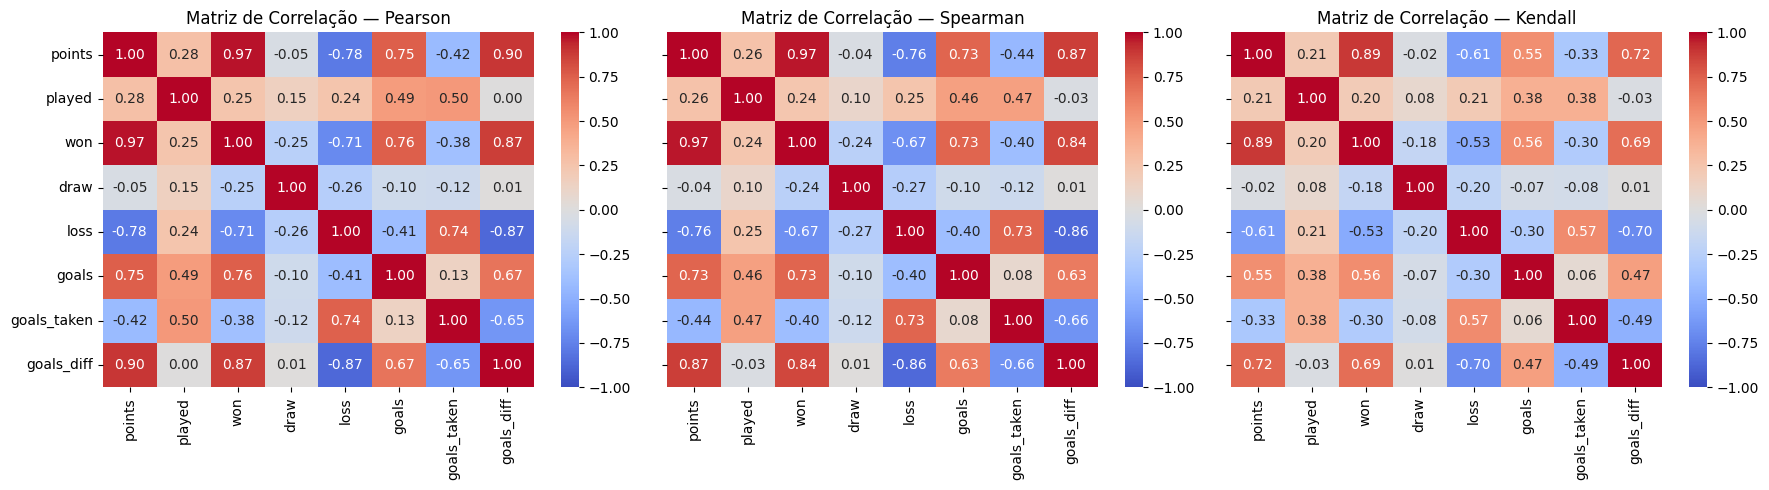

In [ ]:
corr_pearson = df[VARS_QUANT].corr(method="pearson")
corr_spearman = df[VARS_QUANT].corr(method="spearman")
corr_kendall = df[VARS_QUANT].corr(method="kendall")

fig, ax = plt.subplots(1, 3, figsize=(18, 5), sharey=True)

sns.heatmap(
    corr_pearson,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    ax=ax[0]
)

ax[0].set_title("Matriz de Correlação — Pearson")

sns.heatmap(
    corr_spearman,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    ax=ax[1]
)

ax[1].set_title("Matriz de Correlação — Spearman")

sns.heatmap(
    corr_kendall,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    ax=ax[2]
)

ax[2].set_title("Matriz de Correlação — Kendall")

plt.tight_layout()
plt.show()

Como os dados do triângulo superior e inferior são simétricos, poderíamos plotar a matriz de correlação da seguinte forma.

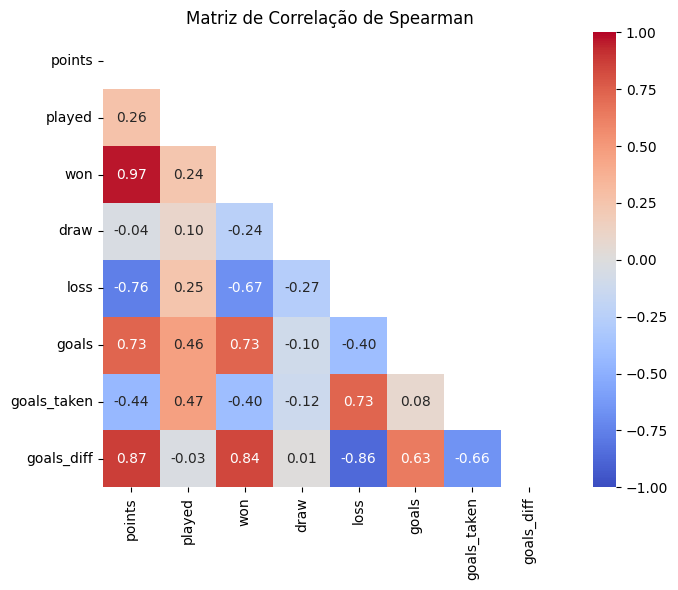

In [ ]:
mask = np.triu(np.ones_like(corr_spearman, dtype=bool))

plt.figure(figsize=(8, 6))

sns.heatmap(
    corr_spearman,
    mask=mask,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    square=True,
    vmin=-1,
    vmax=1
)

plt.title("Matriz de Correlação de Spearman")
plt.tight_layout()
plt.show()

**Pra discutir:** Pearson e Spearman ficaram bastante próximos na maioria das relações, sem grandes divergências. Isso indica que não há sinais fortes de relações monotônicas não lineares. Como a maioria das variáveis não apresentou normalidade, Spearman foi mantido como principal referência.

#### Dispersão (scatter) entre duas variáveis quantitativas

Escolhemos `age` x `thalach` por um motivo de domínio, não só estatístico: existe uma relação fisiológica entre idade e frequência cardíaca máxima, o que torna esse par um bom candidato pra visualizar uma tendência real.

**Nota para quando vocês replicarem no dataset de vocês:** nem sempre vai existir uma relação de domínio óbvia e, nesse caso, uma alternativa é escolher o par com o maior |correlação| na tabela acima, deixando a própria estatística guiar a escolha.

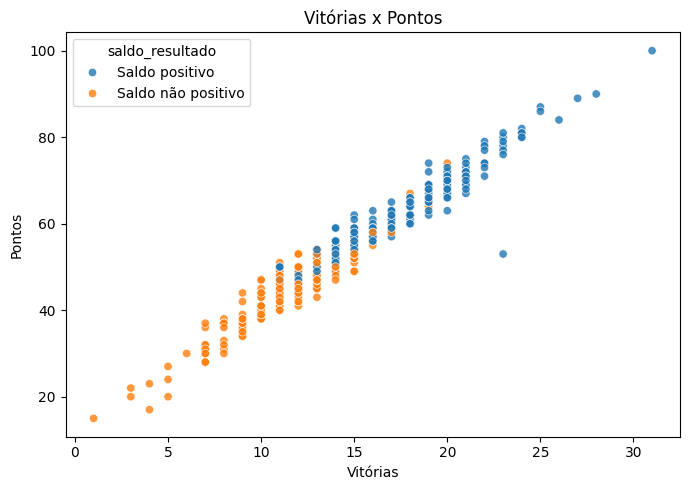

In [ ]:
plt.figure(figsize=(7, 5))

sns.scatterplot(
    data=df,
    x="won",
    y="points",
    hue="saldo_resultado",
    alpha=0.8
)

plt.title("Vitórias x Pontos")
plt.xlabel("Vitórias")
plt.ylabel("Pontos")

plt.tight_layout()
plt.show()

**Pra discutir:** Essa relação é esperada, já que cada vitória contribui diretamente para a pontuação da equipe. Por isso, a correlação muito alta entre vitórias e ponos, confirma visualmente a consistência dos dados.

#### Quantitativa x Qualitativa: Comparando Grupos

Na aula passada listamos **T-Test** (2 grupos) e **ANOVA** (3+ grupos) como testes paramétricos pra comparar uma variável quantitativa entre categorias, mas os dois assumem normalidade dentro de cada grupo.

Já vimos na Seção 3 (tabela generalizada do Shapiro-Wilk) que **nenhuma** das nossas quantitativas passou nesse teste. Isso significa que, tecnicamente, deveríamos usar os equivalentes **não-paramétricos**: **Mann-Whitney U** no lugar do T-Test, e **Kruskal-Wallis** no lugar da ANOVA. Vamos calcular os dois lado a lado pra comparar, mas o resultado não-paramétrico é o que deveríamos reportar como principal.

In [ ]:
resultados_comparacao = []

for col in VARS_QUANT:

    grupo_positivo = df.loc[
        df["saldo_resultado"] == "Saldo positivo",
        col
    ]

    grupo_nao_positivo = df.loc[
        df["saldo_resultado"] == "Saldo não positivo",
        col
    ]


    stat_t, p_t = stats.ttest_ind(
        grupo_positivo,
        grupo_nao_positivo,
        equal_var=False
    )


    stat_u, p_u = stats.mannwhitneyu(
        grupo_positivo,
        grupo_nao_positivo,
        alternative="two-sided"
    )

    resultados_comparacao.append({
        "variavel": col,
        "p_valor_ttest": round(p_t, 5),
        "p_valor_mannwhitney": round(p_u, 5),
        "concordam": (p_t < 0.05) == (p_u < 0.05)
    })

pd.DataFrame(resultados_comparacao).set_index("variavel")

,p_valor_ttest,p_valor_mannwhitney,concordam
variavel,,,
points,0.00000,0.00000,True
played,0.14185,0.17099,True
won,0.00000,0.00000,True
draw,0.60844,0.82545,True
loss,0.00000,0.00000,True
goals,0.00000,0.00000,True
goals_taken,0.00000,0.00000,True
goals_diff,0.00000,0.00000,True


**Pra discutir:** Os testes t de Welch e Mann-Whitney apresentaram a mesma conclusão para todas as variáveis analisadas. Como a maioria das variáveis quantitativas não apresentou normalidade, o teste de Mann-Whitney é a principal referência para interpretação.

As variáveis points, won, loss, goals, goals_taken e goals_diff apresentaram p-valor inferior a 0,05, indicando diferenças estatisticamente significativas entre campanhas com saldo positivo e saldo não positivo.


ANOVA - points entre temporadas: estatística=1.714, p-valor=0.025981
Kruskal-Wallis - points entre temporadas: estatística=31.485, p-valor=0.065956


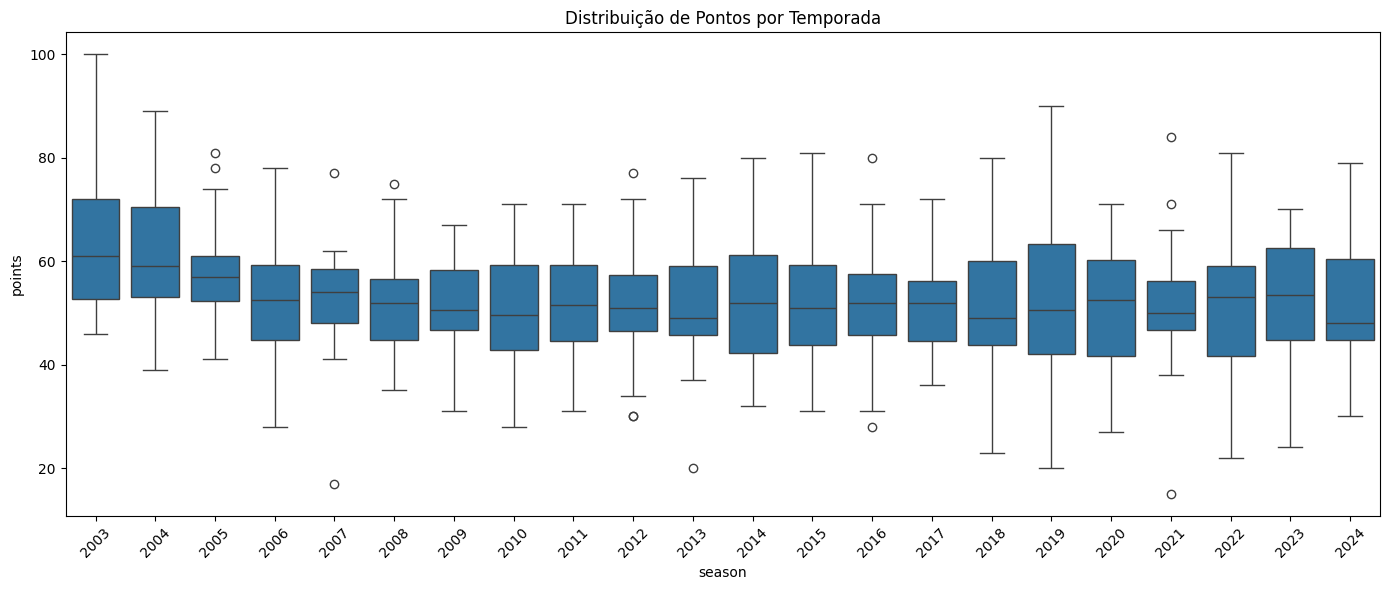

In [ ]:
grupos_season = [
    grupo["points"].values
    for _, grupo in df.groupby("season")
]

stat_anova, p_anova = stats.f_oneway(*grupos_season)
stat_kw, p_kw = stats.kruskal(*grupos_season)

print(
    f"ANOVA - points entre temporadas: "
    f"estatística={stat_anova:.3f}, p-valor={p_anova:.5g}"
)

print(
    f"Kruskal-Wallis - points entre temporadas: "
    f"estatística={stat_kw:.3f}, p-valor={p_kw:.5g}"
)

plt.figure(figsize=(14, 6))

sns.boxplot(
    data=df,
    x="season",
    y="points"
)

plt.title("Distribuição de Pontos por Temporada")
plt.xlabel("season")
plt.ylabel("points")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Pra discutir:** Como a variável points rejeitou normalidade anteriormente, o resultado do Kruskal-Wallis é o mais adequado como referência principal. Portanto, não há evidência estatística suficiente, ao nível de 5%, para afirmar que a distribuição de pontos difere entre as temporadas.

Visualmente, algumas temporadas apresentam medianas e dispersões diferentes, especialmente nos primeiros anos, mas essas diferenças não foram fortes o suficiente para atingir significância estatística no teste não paramétrico.

#### Quantitativa x Qualitativa

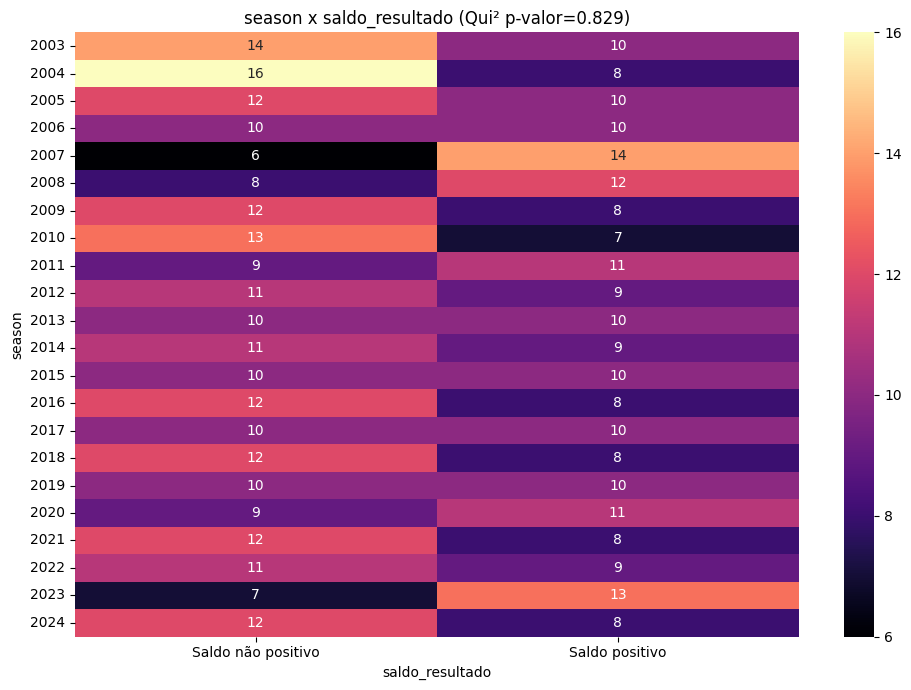

In [ ]:
from scipy import stats
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

contingencia_season = pd.crosstab(
    df["season"],
    df["saldo_resultado"]
)

chi2, p_chi2, dof, esperado = stats.chi2_contingency(contingencia_season)

fig, ax = plt.subplots(figsize=(10, 7))

sns.heatmap(
    contingencia_season,
    annot=True,
    fmt="d",
    cmap="magma",
    ax=ax
)

ax.set_title(
    f"season x saldo_resultado (Qui² p-valor={p_chi2:.4g})"
)

plt.tight_layout()
plt.show()

**Pra discutir:** O teste do Qui-quadrado apresentou p-valor de 0,829, valor superior a 0,05. Portanto, não rejeitamos a hipótese de independência entre season e saldo_resultado.

Isso indica que não há evidência estatística suficiente para afirmar que a proporção de campanhas com saldo positivo ou saldo não positivo varie de forma significativa entre as temporadas.

Visualmente, existem pequenas diferenças entre alguns anos, mas elas parecem compatíveis com variações naturais da amostra, e não com uma associação consistente entre a temporada e o resultado do saldo de gols.

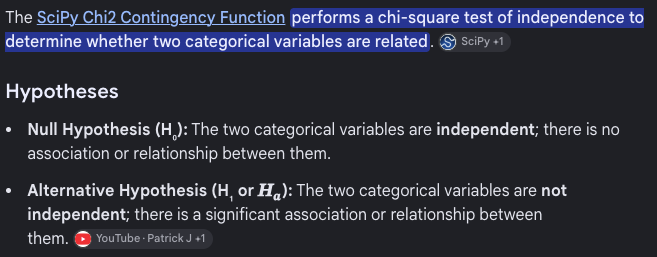

#### Avaliação de Fairness

Olhar o desbalanceamento da base inteira é só metade da história. Uma pergunta recorrente em discussões de **fairness** (justiça algorítmica) é: será que a distribuição do desfecho se comporta igual em diferentes subgrupos de atributos sensíveis (sexo e faixa etária, no nosso caso)? Se não, isso pode refletir um padrão real (ex: idade avançada é fator de risco documentado) ou um viés na forma como os dados foram coletados — de qualquer forma, é algo que vale mapear **antes** de qualquer modelagem.

In [ ]:
print("Desbalanceamento - team:")
print(metrica_desbalanceamento(df["team"]))

print("\nDesbalanceamento - season:")
print(metrica_desbalanceamento(df["season"]))

Desbalanceamento - team:
n_classes                 44.000
razao_desbalanceamento    22.000
entropia_normalizada       0.923
dtype: float64

Desbalanceamento - season:
n_classes                 22.000
razao_desbalanceamento     1.200
entropia_normalizada       0.999
dtype: float64


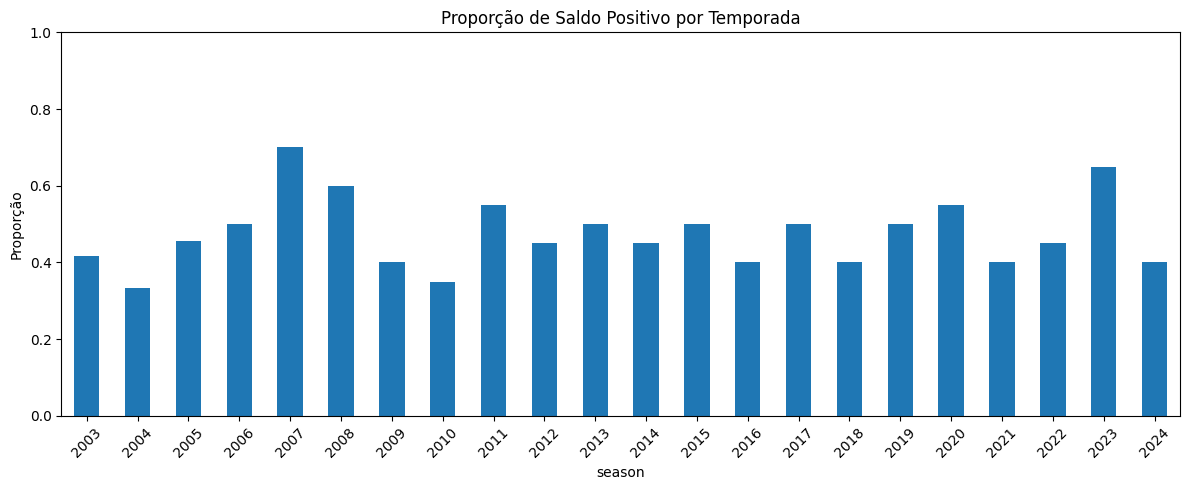

In [ ]:
prop_por_season = pd.crosstab(
    df["season"],
    df["saldo_resultado"],
    normalize="index"
).round(3)

plt.figure(figsize=(12, 5))

prop_por_season["Saldo positivo"].plot(
    kind="bar"
)

plt.title("Proporção de Saldo Positivo por Temporada")
plt.ylabel("Proporção")
plt.xlabel("season")
plt.ylim(0, 1)
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

**Pra discutir:** A proporção de campanhas com saldo positivo varia entre as temporadas, mas não apresenta um padrão consistente ao longo do tempo. Em algumas temporadas a proporção é maior e em outras menor, porém essas diferenças parecem fazer parte da variação natural dos dados.

Isso é coerente com o teste do Qui-quadrado realizado anteriormente, que apresentou p-valor de 0,829 e não indicou associação significativa entre season e saldo_resultado.

Em relação à representatividade, season está muito bem balanceada, com razão de desbalanceamento de 1,20 e entropia normalizada de 0,999. Já team apresenta maior desbalanceamento, com razão de 22, pois alguns clubes participaram de muitas temporadas e outros de poucas.

Esse desbalanceamento em team não indica necessariamente viés ou erro, pois reflete a própria história do campeonato. Entretanto, em uma eventual modelagem preditiva, seria importante considerar que clubes com mais participações possuem muito mais observações e podem exercer maior influência sobre o modelo.

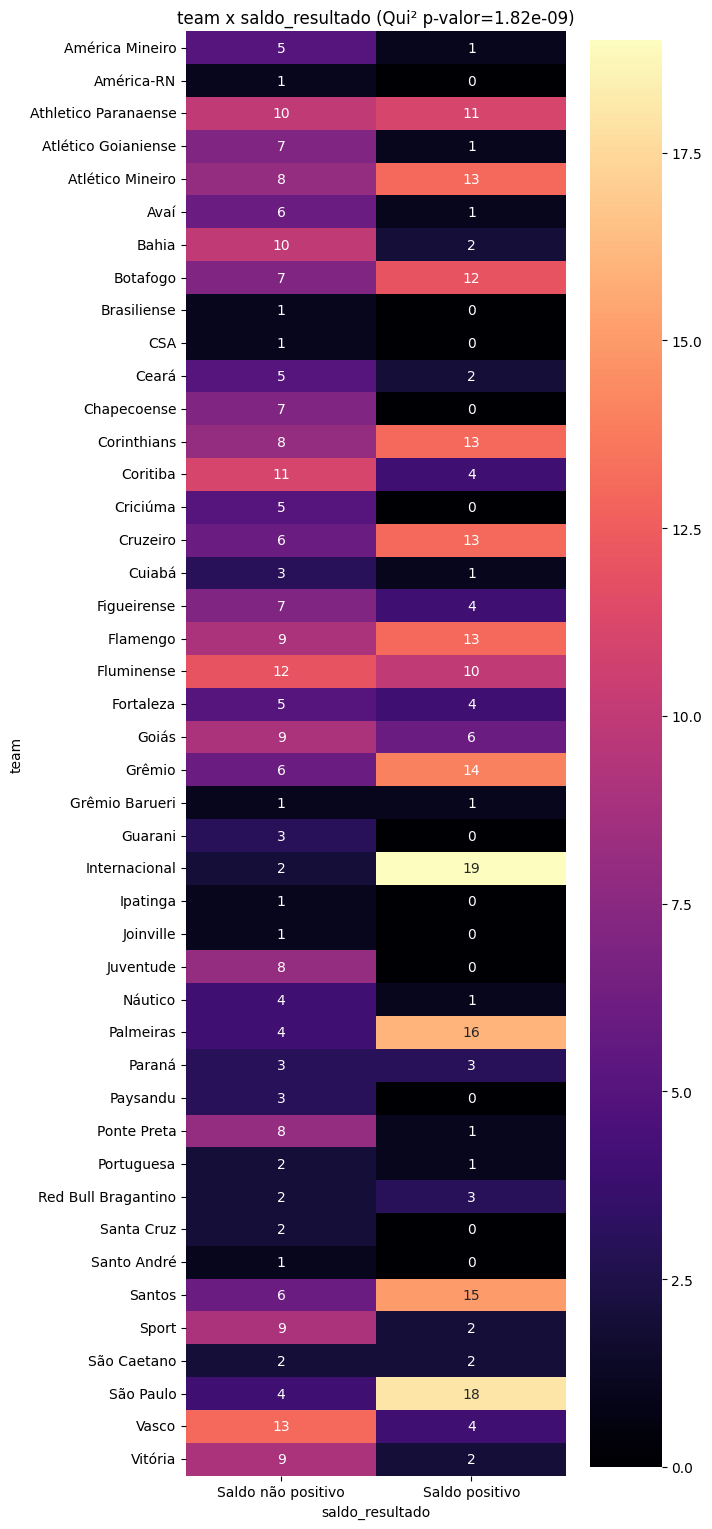

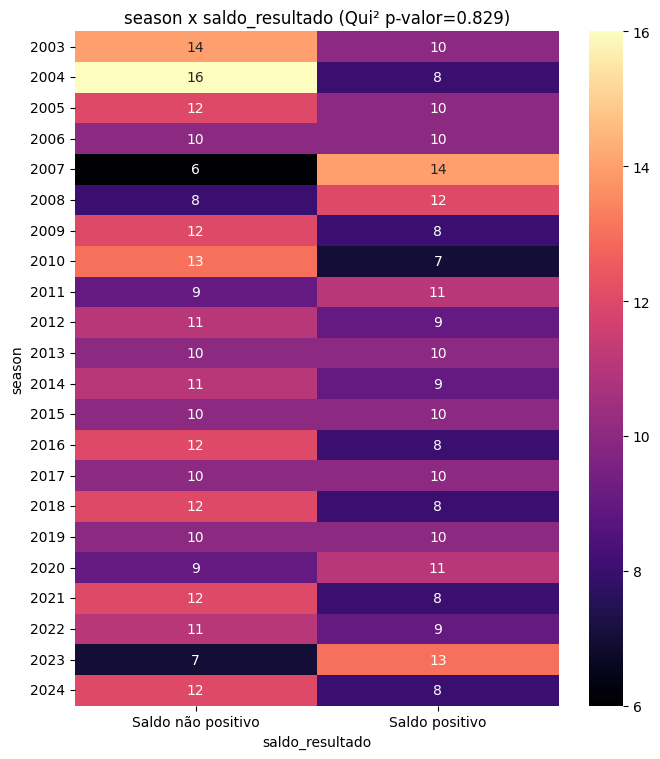

In [ ]:
for atributo in ["team", "season"]:

    contingencia = pd.crosstab(
        df[atributo],
        df["saldo_resultado"]
    )

    chi2, p_valor, gl, esperado = stats.chi2_contingency(contingencia)


    altura = max(6, len(contingencia) * 0.35)

    fig, ax = plt.subplots(figsize=(7, altura))

    sns.heatmap(
        contingencia,
        annot=True,
        fmt="d",
        cmap="magma",
        ax=ax
    )

    ax.set_title(
        f"{atributo} x saldo_resultado "
        f"(Qui² p-valor={p_valor:.4g})"
    )

    plt.tight_layout()
    plt.show()

**Pra discutir:** O teste do Qui-quadrado apresentou p-valor de aproximadamente 1,82 × 10⁻⁹, muito inferior a 0,05. Portanto, rejeitamos a hipótese de independência entre team e saldo_resultado.

Isso indica que existe associação estatisticamente significativa entre o clube e a ocorrência de campanhas com saldo de gols positivo ou não positivo.

O heatmap mostra que alguns clubes apresentam maior frequência de temporadas com saldo positivo, enquanto outros concentram mais campanhas com saldo não positivo.

Entretanto, essa associação não significa que o nome do clube seja a causa direta do resultado. Ela pode refletir diferenças históricas de desempenho, permanência na Série A, investimento, qualidade do elenco e quantidade de temporadas disputadas.

#### Outliers bivariados

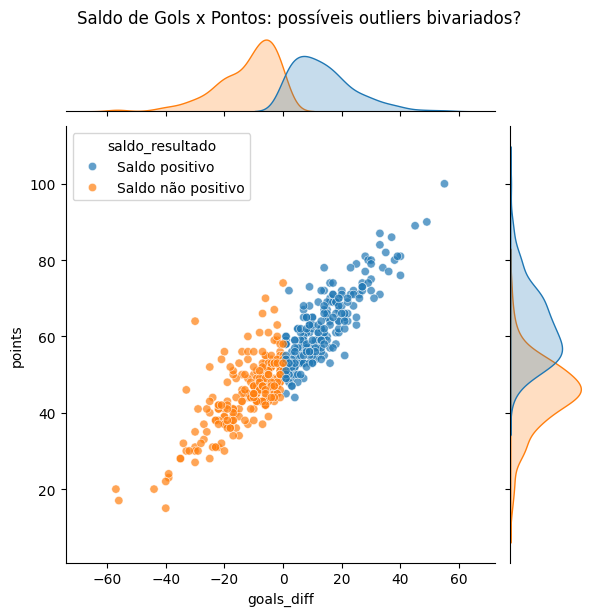

In [ ]:
sns.jointplot(
    data=df,
    x="goals_diff",
    y="points",
    hue="saldo_resultado",
    alpha=0.7,
    height=6
)

plt.suptitle(
    "Saldo de Gols x Pontos: possíveis outliers bivariados?",
    y=1.02
)

plt.show()

**Pra discutir:** A maior parte das observações segue uma relação positiva clara entre goals_diff e points: equipes com melhor saldo de gols tendem a acumular mais pontos.

Alguns pontos se afastam da tendência principal e podem ser considerados possíveis outliers bivariados, pois apresentam combinações incomuns entre saldo de gols e pontuação. Esses casos podem não aparecer como extremos quando cada variável é analisada separadamente, mas se destacam quando observamos as duas em conjunto.

Entretanto, esses pontos não devem ser removidos automaticamente. Eles podem representar campanhas reais e atípicas, portanto precisam ser investigados individualmente antes de qualquer tratamento.

#### Análise Multivariada

##### Matriz de Correlação

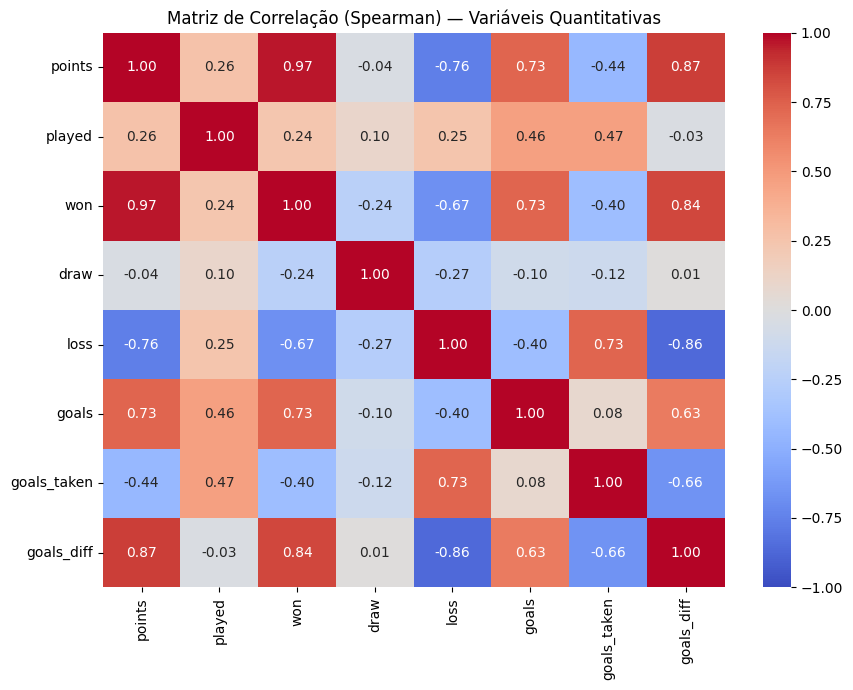

In [ ]:
plt.figure(figsize=(9, 7))

sns.heatmap(
    df[VARS_QUANT].corr(method="spearman"),
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    fmt=".2f"
)

plt.title("Matriz de Correlação (Spearman) — Variáveis Quantitativas")
plt.tight_layout()
plt.show()

**Como interpretar:**


*   |r| < 0.3 ~ fraca,
*   0.3 < |r| < 0.7 ~ moderada,
*  |r| > 0.7 ~ forte.

Alguma correlação chama atenção por ser forte o suficiente pra sugerir redundância entre variáveis?

##### Correlograma

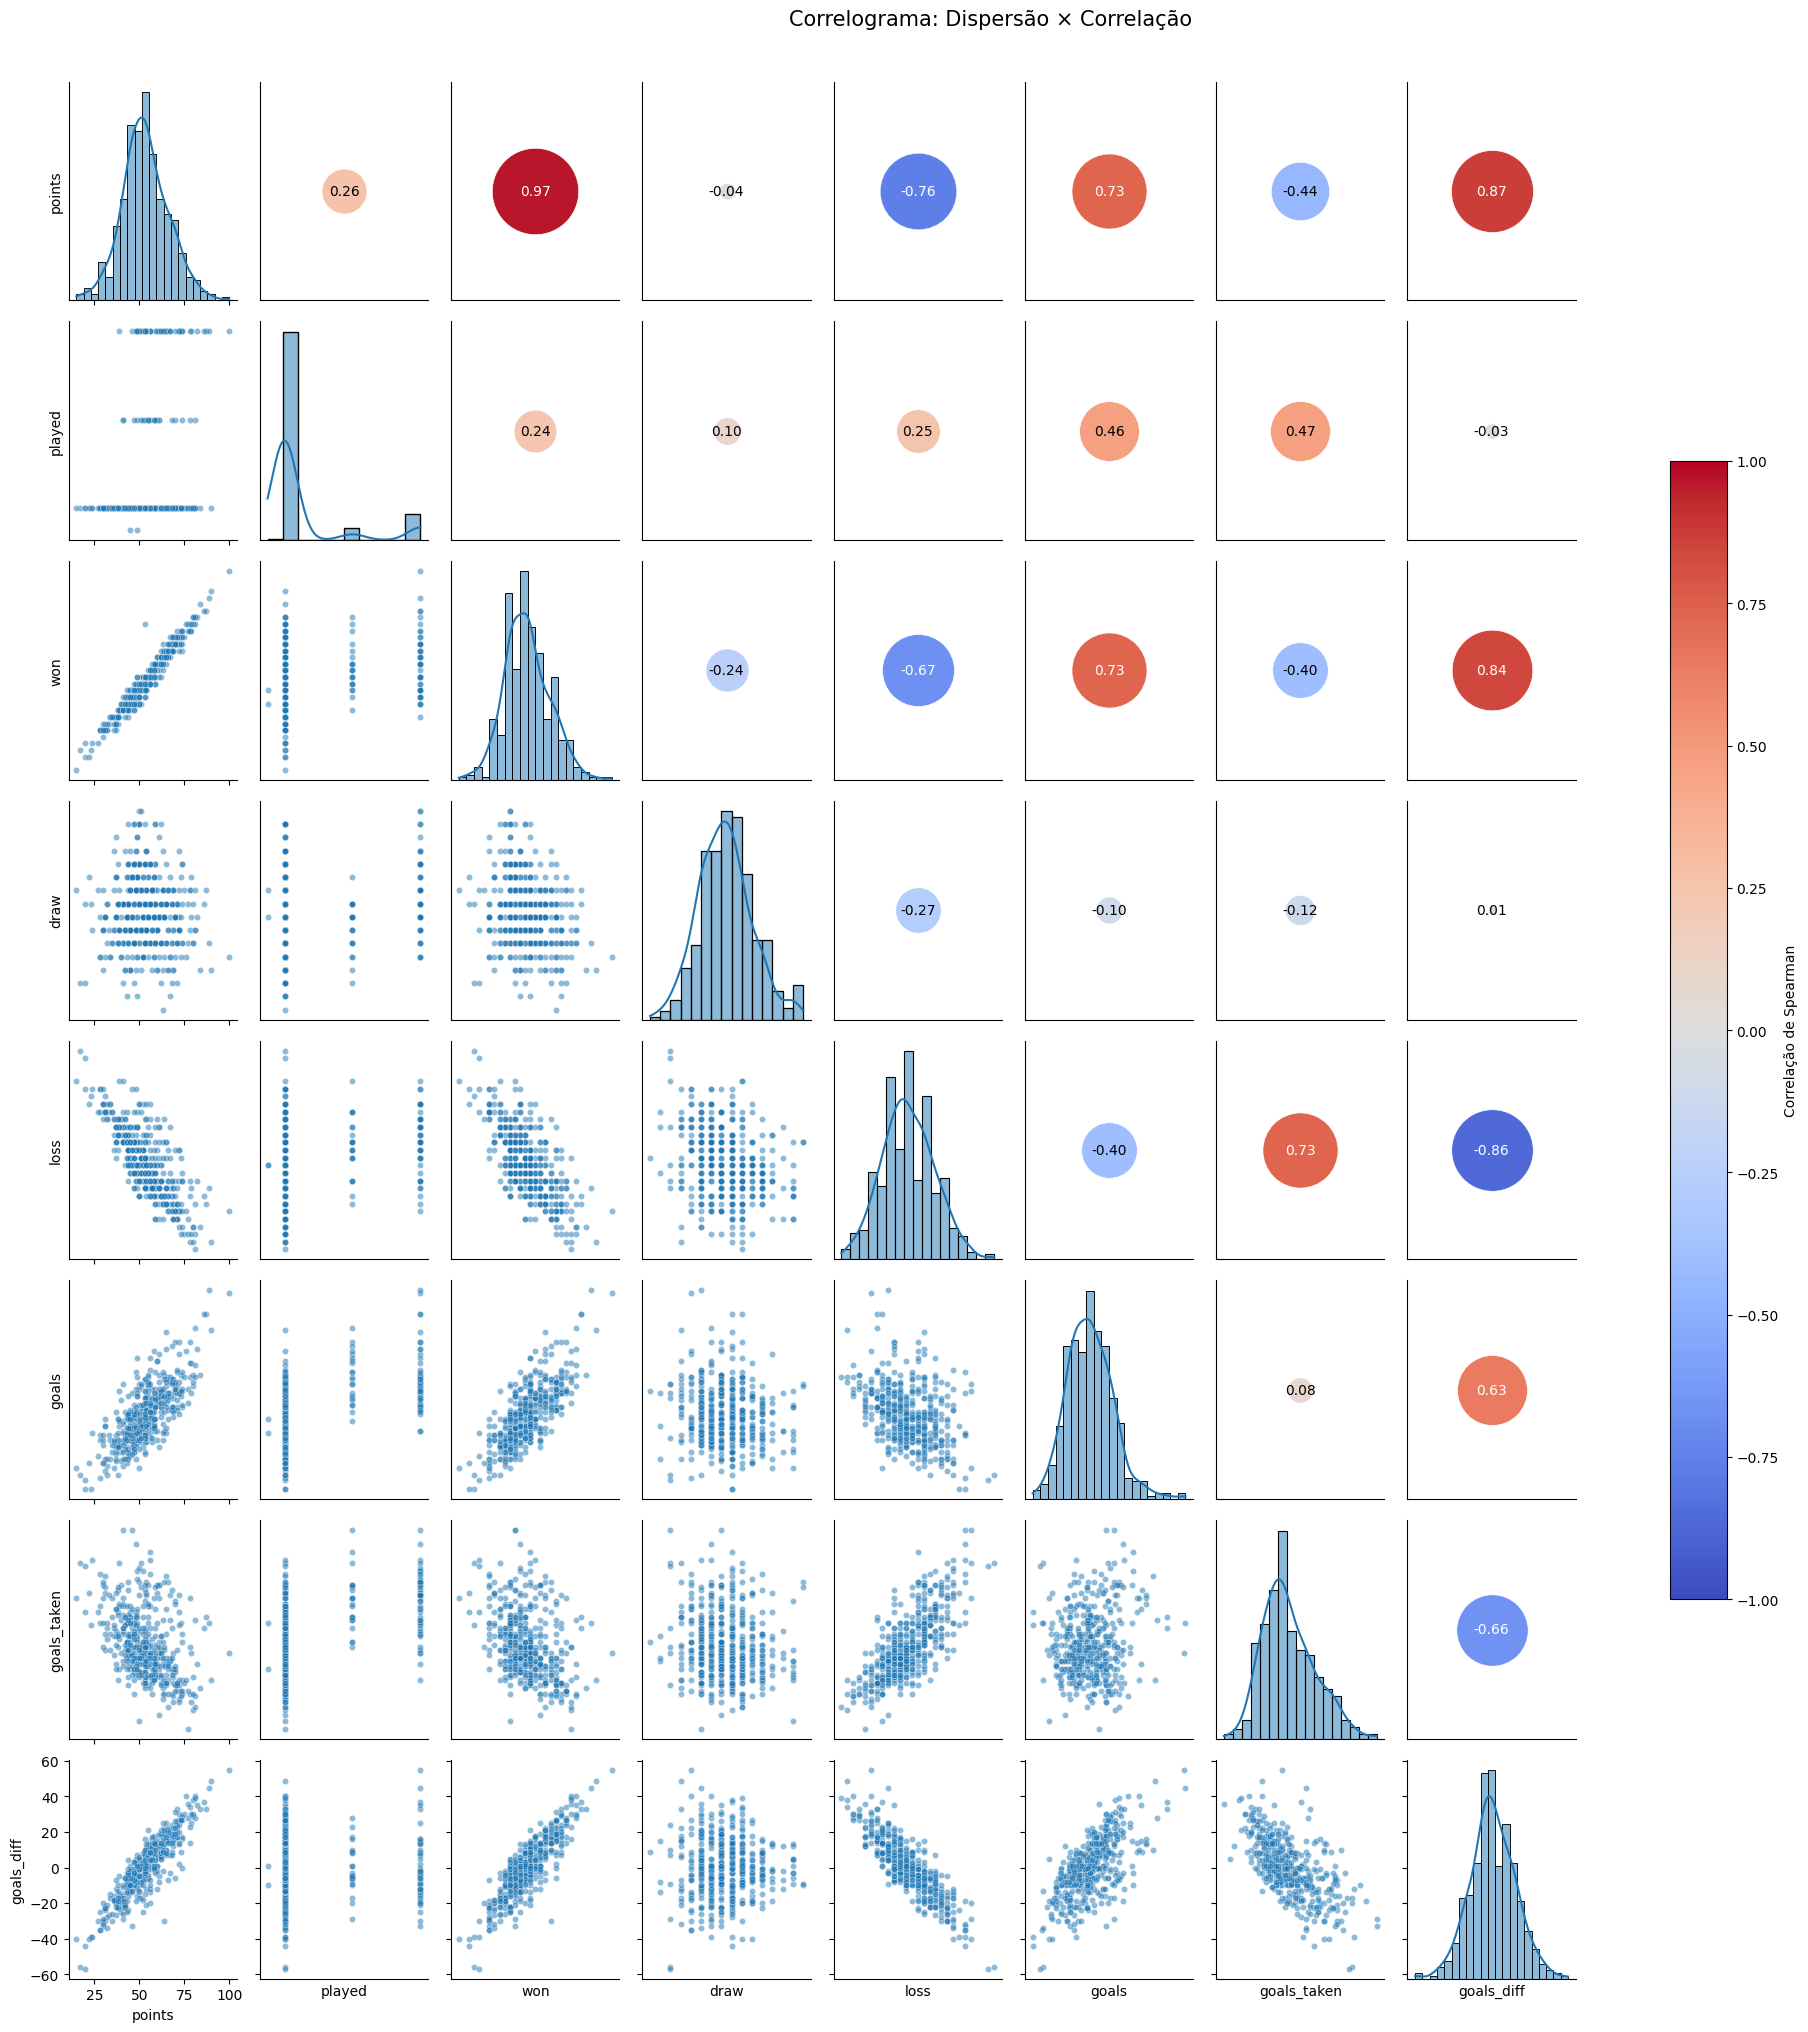

In [ ]:
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize
from scipy.stats import spearmanr

def circulo_correlacao(x, y, **kwargs):
    r, _ = spearmanr(x, y)

    ax = plt.gca()
    ax.scatter(
        [0.5], [0.5],
        s=abs(r) * 4000,
        c=[r],
        cmap="coolwarm",
        vmin=-1,
        vmax=1,
        transform=ax.transAxes,
        edgecolor="white",
        linewidth=0.5
    )

    ax.annotate(
        f"{r:.2f}",
        xy=(0.5, 0.5),
        xycoords=ax.transAxes,
        ha="center",
        va="center",
        fontsize=10,
        color="white" if abs(r) > 0.5 else "black"
    )

    ax.set_xticks([])
    ax.set_yticks([])


g = sns.PairGrid(df[VARS_QUANT], diag_sharey=False)

g.map_lower(
    sns.scatterplot,
    alpha=0.5,
    s=20
)

g.map_diag(
    sns.histplot,
    kde=True
)

g.map_upper(
    circulo_correlacao
)

sm = ScalarMappable(
    norm=Normalize(-1, 1),
    cmap="coolwarm"
)

sm.set_array([])

g.fig.colorbar(
    sm,
    ax=g.axes,
    shrink=0.6,
    label="Correlação de Spearman"
)

g.fig.suptitle(
    "Correlograma: Dispersão × Correlação",
    y=1.02,
    fontsize=15
)

plt.show()

## Hands-on!

Agora é a vez de você realizar uma EDA com os seu conjunto de dados recebidos.

Para isso crie um novo notebook e vamos fazer **em sala** uma EDA seguindo a aula prática que acabamos de ter. Os tópicos desenvolvidos são referências.

Para esse exercício é de suma importância que vocês **elaborem perguntas** e **discutam** os resultados obtidos. Por exemplo, se houver dados faltantes, busque *entender* o porquê e *justifique* sua decisão.

Após o desenvolvimento da EDA em si, é necessário fazer uma síntese considerando:


1.   Principais conclusões em 3 a 5 pontos
2.   Declaração de Uso de IA (Ferramenta utilizada, Para o que foi aplicada e o que foi aceito/modificado/rejeitado e por quê)

O **entregável** será um notebook `ipynb`que trará todo o código, discussão, principais conclusões e declaração de uso de IA.




Principais conclusões:
1°
Desempenho e saldo de gols estão fortemente relacionados.
Campanhas com saldo de gols positivo tendem a apresentar mais pontos, mais vitórias e mais gols marcados, além de menos derrotas e menos gols sofridos. Isso apareceu tanto nos histogramas e boxplots quanto nos testes estatísticos.
2° As variáveis mais relacionadas ao desempenho são won, loss e goals_diff.
Pela correlação de Spearman, points apresentou correlação muito forte com won e goals_diff, além de correlação negativa forte com loss. Algumas dessas relações são esperadas pela própria definição das variáveis, como pontos dependerem diretamente de vitórias e empates.
3° O número de jogos (played) varia principalmente por mudanças históricas no formato do campeonato.
A variável apresentou forte assimetria e valores considerados outliers pelo IQR, mas esses valores não foram tratados como erros, pois refletem temporadas com diferentes quantidades de clubes e partidas.
4° Os outliers encontrados foram, em sua maioria, mantidos.
Valores extremos de pontos, gols, vitórias, derrotas e saldo de gols podem representar campanhas reais e excepcionais. Portanto, não houve justificativa para removê-los automaticamente.
5° Não foram encontrados valores ausentes e a maioria das variáveis não apresentou normalidade.
Por isso, em análises inferenciais, foram priorizados métodos não paramétricos, como Mann-Whitney, Kruskal-Wallis e correlação de Spearman.
Declaração de Uso de IA



Declaração de Uso de Inteligência Artificial

Foi utilizada a ferramenta ChatGPT como apoio durante o desenvolvimento desta análise exploratória de dados.

A IA foi utilizada principalmente para:

auxiliar na adaptação dos exemplos apresentados em aula para o dataset do Campeonato Brasileiro;
explicar conceitos estatísticos e auxiliar na interpretação de gráficos e resultados;
identificar e corrigir erros de código;
sugerir formas de visualização e organização da análise.

As sugestões fornecidas pela IA foram analisadas antes de serem utilizadas. Algumas foram modificadas ou rejeitadas quando não faziam sentido para o contexto do dataset. Por exemplo, inicialmente foi considerada a criação de uma variável baseada no G4, mas essa abordagem foi descartada por não acrescentar informação relevante à análise. Também optamos por não remover automaticamente os outliers, pois muitos deles representavam dados legítimos do campeonato.

As decisões finais sobre tratamento dos dados, escolha das análises e interpretação dos resultados foram realizadas considerando o contexto do dataset e os conteúdos apresentados em aula.

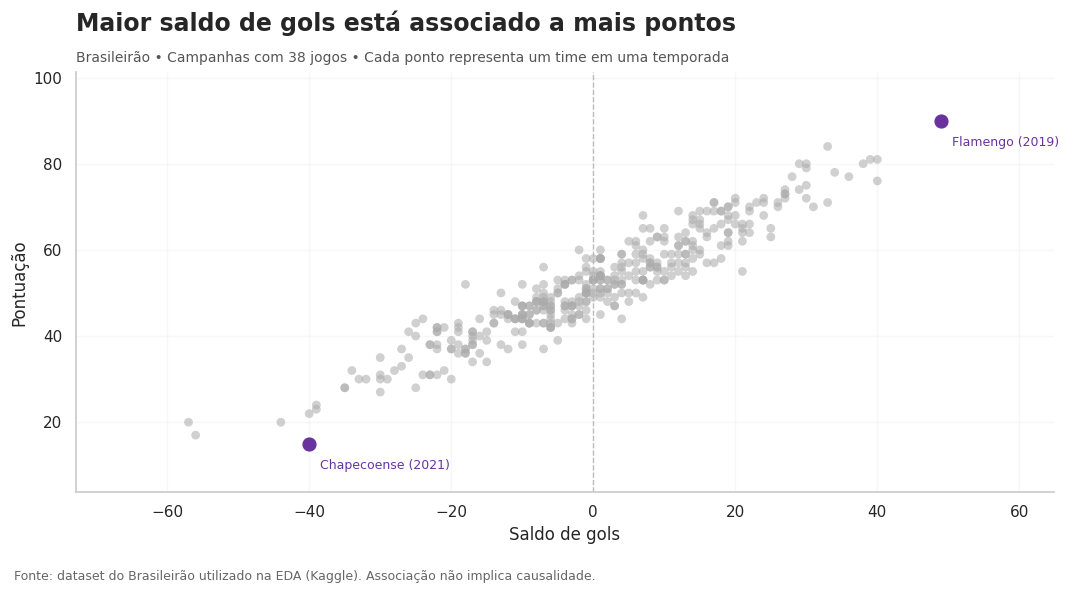

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [5]:
import matplotlib.pyplot as plt
from google.colab import files

# Usa campanhas com 38 jogos para tornar a comparação mais justa.
dados = df.loc[df["played"] == 38].dropna(
    subset=["goals_diff", "points"]
).copy()

fig, ax = plt.subplots(figsize=(11, 6))

ax.scatter(
    dados["goals_diff"], dados["points"],
    color="#AAAAAA", alpha=0.55, s=40, edgecolors="none"
)

# Destaca as campanhas com maior e menor pontuação.
destaques = dados.loc[
    [dados["points"].idxmax(), dados["points"].idxmin()]
].drop_duplicates()

ax.scatter(
    destaques["goals_diff"], destaques["points"],
    color="#6A329F", s=85, zorder=3
)

for _, linha in destaques.iterrows():
    ax.annotate(
        f'{linha["team"]} ({int(linha["season"])})',
        (linha["goals_diff"], linha["points"]),
        xytext=(8, -18),
        textcoords="offset points",
        fontsize=9,
        color="#6A329F"
    )

ax.set_title(
    "Maior saldo de gols está associado a mais pontos",
    loc="left", fontsize=17, fontweight="bold", pad=30
)
ax.text(
    0, 1.025,
    "Brasileirão • Campanhas com 38 jogos • Cada ponto representa um time em uma temporada",
    transform=ax.transAxes, fontsize=10, color="#555555"
)

ax.set_xlabel("Saldo de gols", fontsize=12)
ax.set_ylabel("Pontuação", fontsize=12)
ax.axvline(0, color="#BBBBBB", linewidth=1, linestyle="--")
ax.set_axisbelow(True)
ax.grid(alpha=0.15)
ax.spines[["top", "right"]].set_visible(False)
ax.margins(x=0.15, y=0.15)

fig.text(
    0.02, 0.02,
    "Fonte: dataset do Brasileirão utilizado na EDA (Kaggle). "
    "Associação não implica causalidade.",
    fontsize=9, color="#666666"
)

plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.savefig("grafico_saldo_pontuacao.png", dpi=300, bbox_inches="tight")
plt.show()

files.download("grafico_saldo_pontuacao.png")